# Multi-Sample scRNA-Seq IMPROVED Re-analysis Pipeline - pt3 Differential Expression

IMPROVED, PATCHED AND AUTOMATED Reanalysis of: 
* Melms, J.C., Biermann, J., Huang, H. et al. A molecular single-cell lung atlas of lethal COVID-19. Nature 595, 114–119 (2021). https://doi.org/10.1038/s41586-021-03569-1

    - https://www.nature.com/articles/s41586-021-03569-1

    - download the "RAW.tar" data. GEO with accession number GSE171524

  **INCLUDES:**
  - Automated functions for plotting umaps
  - optimized scvi layers for analysis and plotting (normalization only in required data)
  - Step by step manual cell labeling and Biological interpretation

### **by José Alberto Isidoro Sánchez**

##### GUIDE: https://youtu.be/uvyG9yLuNSE?si=fzfICWtsWN2JSAaj

In [ ]:
#conda install scanpy


----------------
----------------
----------------
# Overview
-----------------
-----------------
-----------------

This repository contains an end-to-end processing pipeline for single-cell RNA sequencing (scRNA-seq) datasets using scvi-tools and scanpy. The workflow automates sample-level quality control, deep learning-based doublet removal, and multi-sample cohort integration to prepare raw single-cell count matrices for downstream biological analysis.  

Technical Workflow Steps
1. **Per-Sample Preprocessing & Doublet Detection (pt1)**
* Iterative Pipeline Execution: Each raw sequencing sample (.csv.gz or .h5ad) is processed individually to account for sample-specific library sizes and experimental batch effects.  
* Quality Filtering: Initial low-quality cell removal based on standard single-cell metrics (mitochondrial read percentage, minimum/maximum gene detection counts).
* Deep Learning Doublet Removal:
    * Fits a sample-specific Variational Autoencoder (scVI VAE) on unnormalized counts.
    * Trains a SOLO model (semi-supervised feed-forward neural network) using the learned VAE latent space to classify true single cells versus simulated doublets.
* Export Clean Artifacts: Filters out predicted doublets and saves purified sample objects as individual .h5ad files.  



2. **Cohort-Wide Integration & Downstream Analysis (pt2)**

* Merging: Aggregates purified, single-sample .h5ad objects into a unified, cohort-level AnnData object.
* Batch Integration: Retrains an integrated scVI generative model across all combined samples to remove technical batch effects while preserving true biological variation.
* Dimensionality Reduction & Clustering: Computes latent space embeddings (UMAP) and unsupervised graph-based clustering (Leiden/Louvain) for global cell-type annotation.




  
3. **Important Architectural Considerations**
Why Doublet Detection Runs Per Sample
* Doublets—microfluidic droplets that accidentally capture two or more cells—are artifact events dictated by the physical cell density and microfluidic loading conditions of an individual library preparation.
* Because doublet frequencies and expression profiles vary strictly by sample batch:
    * scVI and SOLO models are trained per sample. Training a single VAE/SOLO model across the whole cohort prior to integration leads to incorrect doublet classification.
    * Models are not applied across the entire cohort at once. Doublets must be identified and removed prior to cohort-wide batch correction and co-embedding.


------------
-----------
# 7.- Downstream Analysis

------------
-----------

In [304]:
adata = sc.read_h5ad("manual_labeled.h5ad")
# 2. Load the trained scVI model and link it to your AnnData
model_combined = scvi.model.SCVI.load("scvi_model_combined", adata=adata)

print(" Successfully loaded AnnData and scVI model!")

In [305]:
adata.obs.Sample.unique().tolist()

['C51ctr', 'C52ctr', 'L03cov', 'L04cov']

In [306]:
def map_condition(sample_name):
    if 'cov' in sample_name.lower():
        return 'COVID19'
    elif 'ctr' in sample_name.lower() or 'control' in sample_name.lower():
        return 'control'
    else:
        return 'unknown'

# Re-assign condition column cleanly
adata.obs['condition'] = adata.obs['Sample'].map(map_condition)

In [307]:
#New condition column at the end
adata.obs

,Sample,doublet,n_genes,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_ribo,pct_counts_ribo,_scvi_batch,_scvi_labels,leiden,leiden_res_0_7,_scvi_raw_norm_scaling,leiden_res_0_9,cell_type,condition
CGTTCTGGTACTAGCT-1_C51ctr,C51ctr,False,2434,2434,6047.0,6.0,0.099223,1.0,0.016537,0,0,1,1,1.670007,1,AT2_Cells,control
CTGGCAGGTTCGGTAT-1_C51ctr,C51ctr,False,2444,2444,5899.0,307.0,5.204272,5.0,0.084760,0,0,1,1,1.717918,1,AT2_Cells,control
ACACCAACACAACGCC-1_C51ctr,C51ctr,False,2451,2451,5497.0,0.0,0.000000,3.0,0.054575,0,0,2,3,1.839588,2,AT1_Cells,control
CCTCAACCATACAGGG-1_C51ctr,C51ctr,False,2276,2276,5434.0,38.0,0.699301,0.0,0.000000,0,0,10,11,1.856665,10,Classical Monocytes,control
ACAAAGATCCACAGGC-1_C51ctr,C51ctr,False,2310,2310,5504.0,1.0,0.018169,1.0,0.018169,0,0,1,1,1.834862,1,AT2_Cells,control
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GTAGAGGTCAAAGGTA-1_L04cov,L04cov,False,352,352,402.0,3.0,0.746269,6.0,1.492537,0,0,0,0,25.062656,0,Alveolar Macrophages,COVID19
TTTGGAGCAGTTGTTG-1_L04cov,L04cov,False,343,343,411.0,0.0,0.000000,0.0,0.000000,0,0,4,4,24.875622,4,Fibroblasts,COVID19
GGGACAACAAATACGA-1_L04cov,L04cov,False,360,360,410.0,0.0,0.000000,0.0,0.000000,0,0,0,0,24.630541,0,Alveolar Macrophages,COVID19
CTGTGGGAGAGTATAC-1_L04cov,L04cov,False,349,349,407.0,0.0,0.000000,0.0,0.000000,0,0,4,4,25.380711,4,Fibroblasts,COVID19


In [308]:
adata.obs.groupby(['Sample']).count()

/var/folders/w9/bwws86216wgb0hvxvlbzqqt40000gn/T/ipykernel_69202/2812466228.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  adata.obs.groupby(['Sample']).count()


,doublet,n_genes,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_ribo,pct_counts_ribo,_scvi_batch,_scvi_labels,leiden,leiden_res_0_7,_scvi_raw_norm_scaling,leiden_res_0_9,cell_type,condition
Sample,,,,,,,,,,,,,,,,
C51ctr,5977,5977,5977,5977,5977,5977,5977,5977,5977,5977,5977,5977,5977,5977,5977,5977
C52ctr,4422,4422,4422,4422,4422,4422,4422,4422,4422,4422,4422,4422,4422,4422,4422,4422
L03cov,4949,4949,4949,4949,4949,4949,4949,4949,4949,4949,4949,4949,4949,4949,4949,4949
L04cov,3557,3557,3557,3557,3557,3557,3557,3557,3557,3557,3557,3557,3557,3557,3557,3557


In [302]:
## CONVERT TO DICTIONARY TO CALL EASILY TOTALC ELLS FOR A SAMPLE:
num_tot_cells = adata.obs.groupby(['Sample']).count()
num_tot_cells = dict(zip(num_tot_cells.index, num_tot_cells.doublet))
num_tot_cells

/var/folders/w9/bwws86216wgb0hvxvlbzqqt40000gn/T/ipykernel_69202/1389590742.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  num_tot_cells = adata.obs.groupby(['Sample']).count()


{'C51ctr': 5977, 'C52ctr': 4422, 'L03cov': 4949, 'L04cov': 3557}

In [310]:
# Get cell counts per condition per cell type
counts_df = adata.obs.groupby(['condition', 'cell_type'], observed=True).size().unstack(fill_value=0)

# Calculate proportions per condition
proportions_df = counts_df.div(counts_df.sum(axis=1), axis=0) * 100

print("--- Cell Counts per Condition ---")
display(counts_df)

print("\n--- Cell Type Percentages (%) per Condition ---")
display(proportions_df.round(2))

--- Cell Counts per Condition ---


cell_type,AT1_Cells,AT2_Cells,Alveolar Macrophages,Ciliated,Classical Monocytes,Endothelial_Lymphatic,Endothelial_Vascular,Endothelial_general,Fibroblasts,Mast_Cells,Monocyte-Derived Macrophages,NK_Cells,Non-Classical Monocytes,Plasma_cells,Residual Alveolar Macrophages,Secretory_Club / Airway_Secretory,Smooth Muscle / Pericytes,T_CD8_Cytotoxic
condition,,,,,,,,,,,,,,,,,,
COVID19,236,91,3215,13,11,185,199,56,1170,120,240,192,127,1089,37,269,134,1122
control,1840,2685,85,269,441,78,598,334,1048,176,312,364,221,57,98,174,223,1396



--- Cell Type Percentages (%) per Condition ---


cell_type,AT1_Cells,AT2_Cells,Alveolar Macrophages,Ciliated,Classical Monocytes,Endothelial_Lymphatic,Endothelial_Vascular,Endothelial_general,Fibroblasts,Mast_Cells,Monocyte-Derived Macrophages,NK_Cells,Non-Classical Monocytes,Plasma_cells,Residual Alveolar Macrophages,Secretory_Club / Airway_Secretory,Smooth Muscle / Pericytes,T_CD8_Cytotoxic
condition,,,,,,,,,,,,,,,,,,
COVID19,2.77,1.07,37.80,0.15,0.13,2.17,2.34,0.66,13.75,1.41,2.82,2.26,1.49,12.80,0.43,3.16,1.58,13.19
control,17.69,25.82,0.82,2.59,4.24,0.75,5.75,3.21,10.08,1.69,3.00,3.50,2.13,0.55,0.94,1.67,2.14,13.42


In [311]:
#Groupping observation data by sample and other caths....
# Updated groupby with observed=True to silence warning and suppress unobserved combinations
sample_counts = adata.obs.groupby(['Sample', 'condition', 'cell_type'], observed=True).size().unstack(fill_value=0)

display(sample_counts)

,cell_type,AT1_Cells,AT2_Cells,Alveolar Macrophages,Ciliated,Classical Monocytes,Endothelial_Lymphatic,Endothelial_Vascular,Endothelial_general,Fibroblasts,Mast_Cells,Monocyte-Derived Macrophages,NK_Cells,Non-Classical Monocytes,Plasma_cells,Residual Alveolar Macrophages,Secretory_Club / Airway_Secretory,Smooth Muscle / Pericytes,T_CD8_Cytotoxic
Sample,condition,,,,,,,,,,,,,,,,,,
C51ctr,control,832,784,49,268,127,31,386,221,688,150,234,342,149,56,81,166,155,1258
C52ctr,control,1008,1901,36,1,314,47,212,113,360,26,78,22,72,1,17,8,68,138
L03cov,COVID19,181,69,1880,2,6,129,118,53,753,76,171,145,54,463,34,198,110,507
L04cov,COVID19,55,22,1335,11,5,56,81,3,417,44,69,47,73,626,3,71,24,615


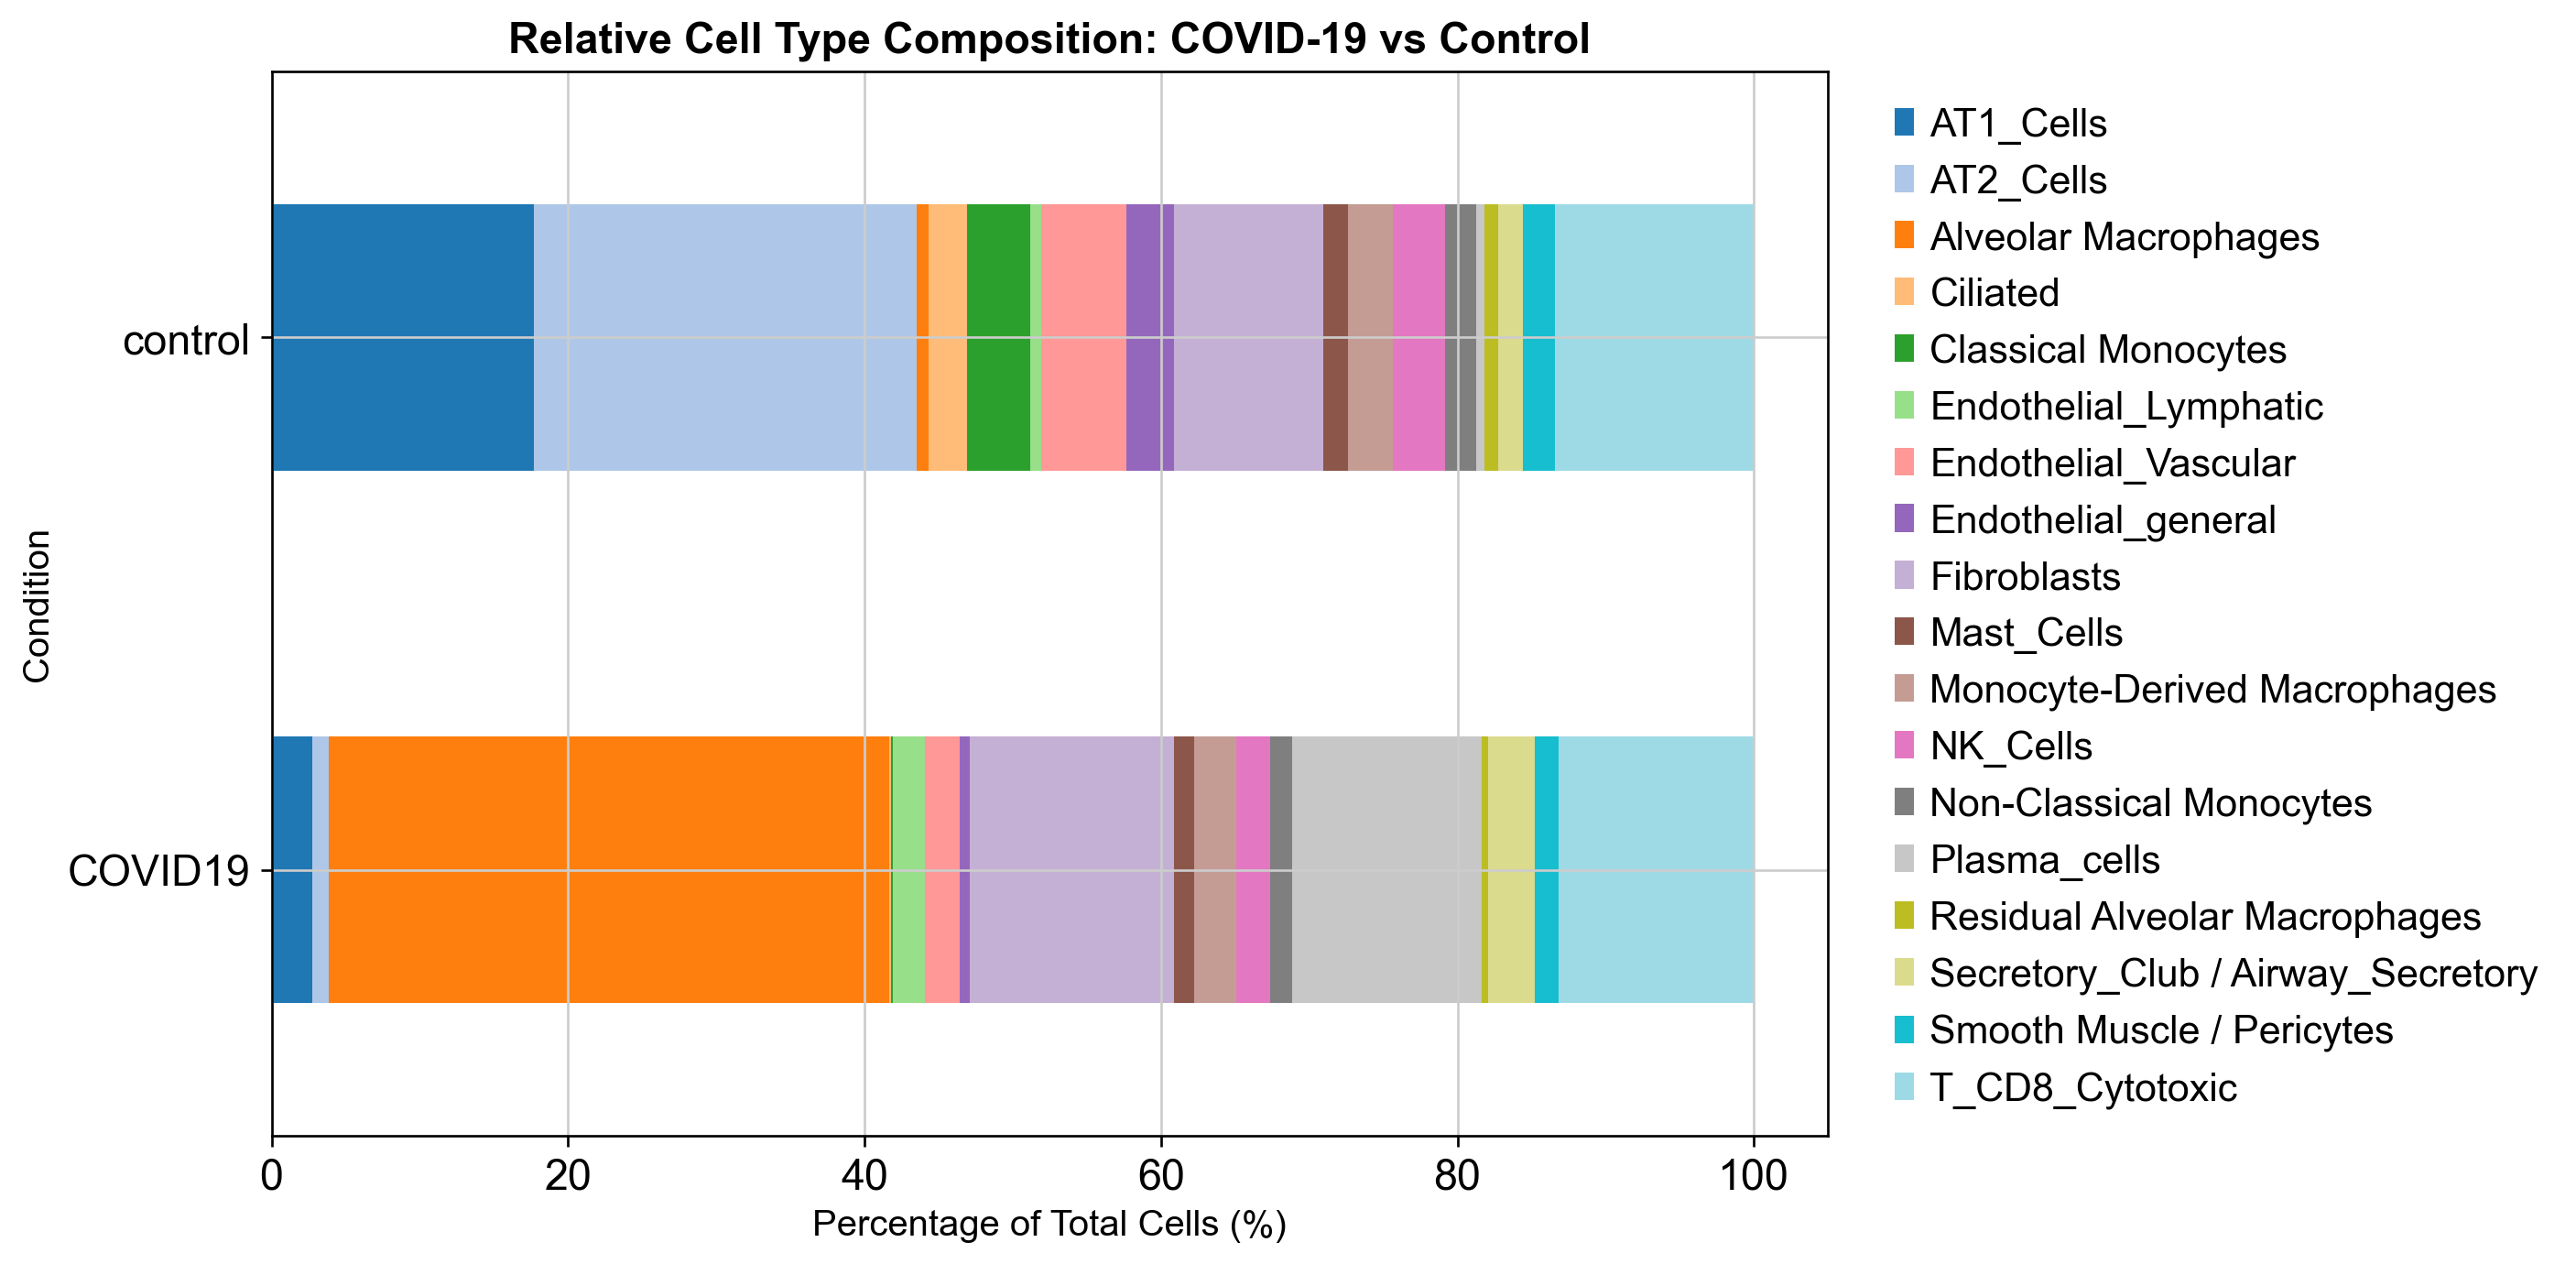

In [313]:
import matplotlib.pyplot as plt

# Plot stacked bar chart of relative cell type proportions per condition
ax = proportions_df.plot(
    kind="barh", 
    stacked=True, 
    figsize=(12, 6), 
    colormap="tab20"
)

plt.title("Relative Cell Type Composition: COVID-19 vs Control", fontsize=14, fontweight="bold")
plt.xlabel("Percentage of Total Cells (%)", fontsize=12)
plt.ylabel("Condition", fontsize=12)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

In [314]:
# Group and drop unobserved combination rows
cell_type_counts = adata.obs.groupby(['Sample', 'condition', 'cell_type'], observed=True).count()

# Reset index to bring Sample, condition, and cell_type back as columns
cell_type_counts = cell_type_counts.reset_index()

# Select the metadata columns + one count column (e.g., 'doublet' represents total cell count)
cell_type_counts = cell_type_counts[['Sample', 'condition', 'cell_type', 'doublet']].rename(
    columns={'doublet': 'cell_count'}
)

display(cell_type_counts)

,Sample,condition,cell_type,cell_count
0,C51ctr,control,AT1_Cells,832
1,C51ctr,control,AT2_Cells,784
2,C51ctr,control,Alveolar Macrophages,49
3,C51ctr,control,Ciliated,268
4,C51ctr,control,Classical Monocytes,127
...,...,...,...,...
67,L04cov,COVID19,Plasma_cells,626
68,L04cov,COVID19,Residual Alveolar Macrophages,3
69,L04cov,COVID19,Secretory_Club / Airway_Secretory,71
70,L04cov,COVID19,Smooth Muscle / Pericytes,24


In [315]:
cell_type_counts['total_cells_sample'] = cell_type_counts.Sample.map(num_tot_cells).astype(int)

cell_type_counts['frequency'] = cell_type_counts.cell_count/ cell_type_counts.total_cells_sample

cell_type_counts

,Sample,condition,cell_type,cell_count,total_cells_sample,frequency
0,C51ctr,control,AT1_Cells,832,5977,0.139200
1,C51ctr,control,AT2_Cells,784,5977,0.131169
2,C51ctr,control,Alveolar Macrophages,49,5977,0.008198
3,C51ctr,control,Ciliated,268,5977,0.044839
4,C51ctr,control,Classical Monocytes,127,5977,0.021248
...,...,...,...,...,...,...
67,L04cov,COVID19,Plasma_cells,626,3557,0.175991
68,L04cov,COVID19,Residual Alveolar Macrophages,3,3557,0.000843
69,L04cov,COVID19,Secretory_Club / Airway_Secretory,71,3557,0.019961
70,L04cov,COVID19,Smooth Muscle / Pericytes,24,3557,0.006747


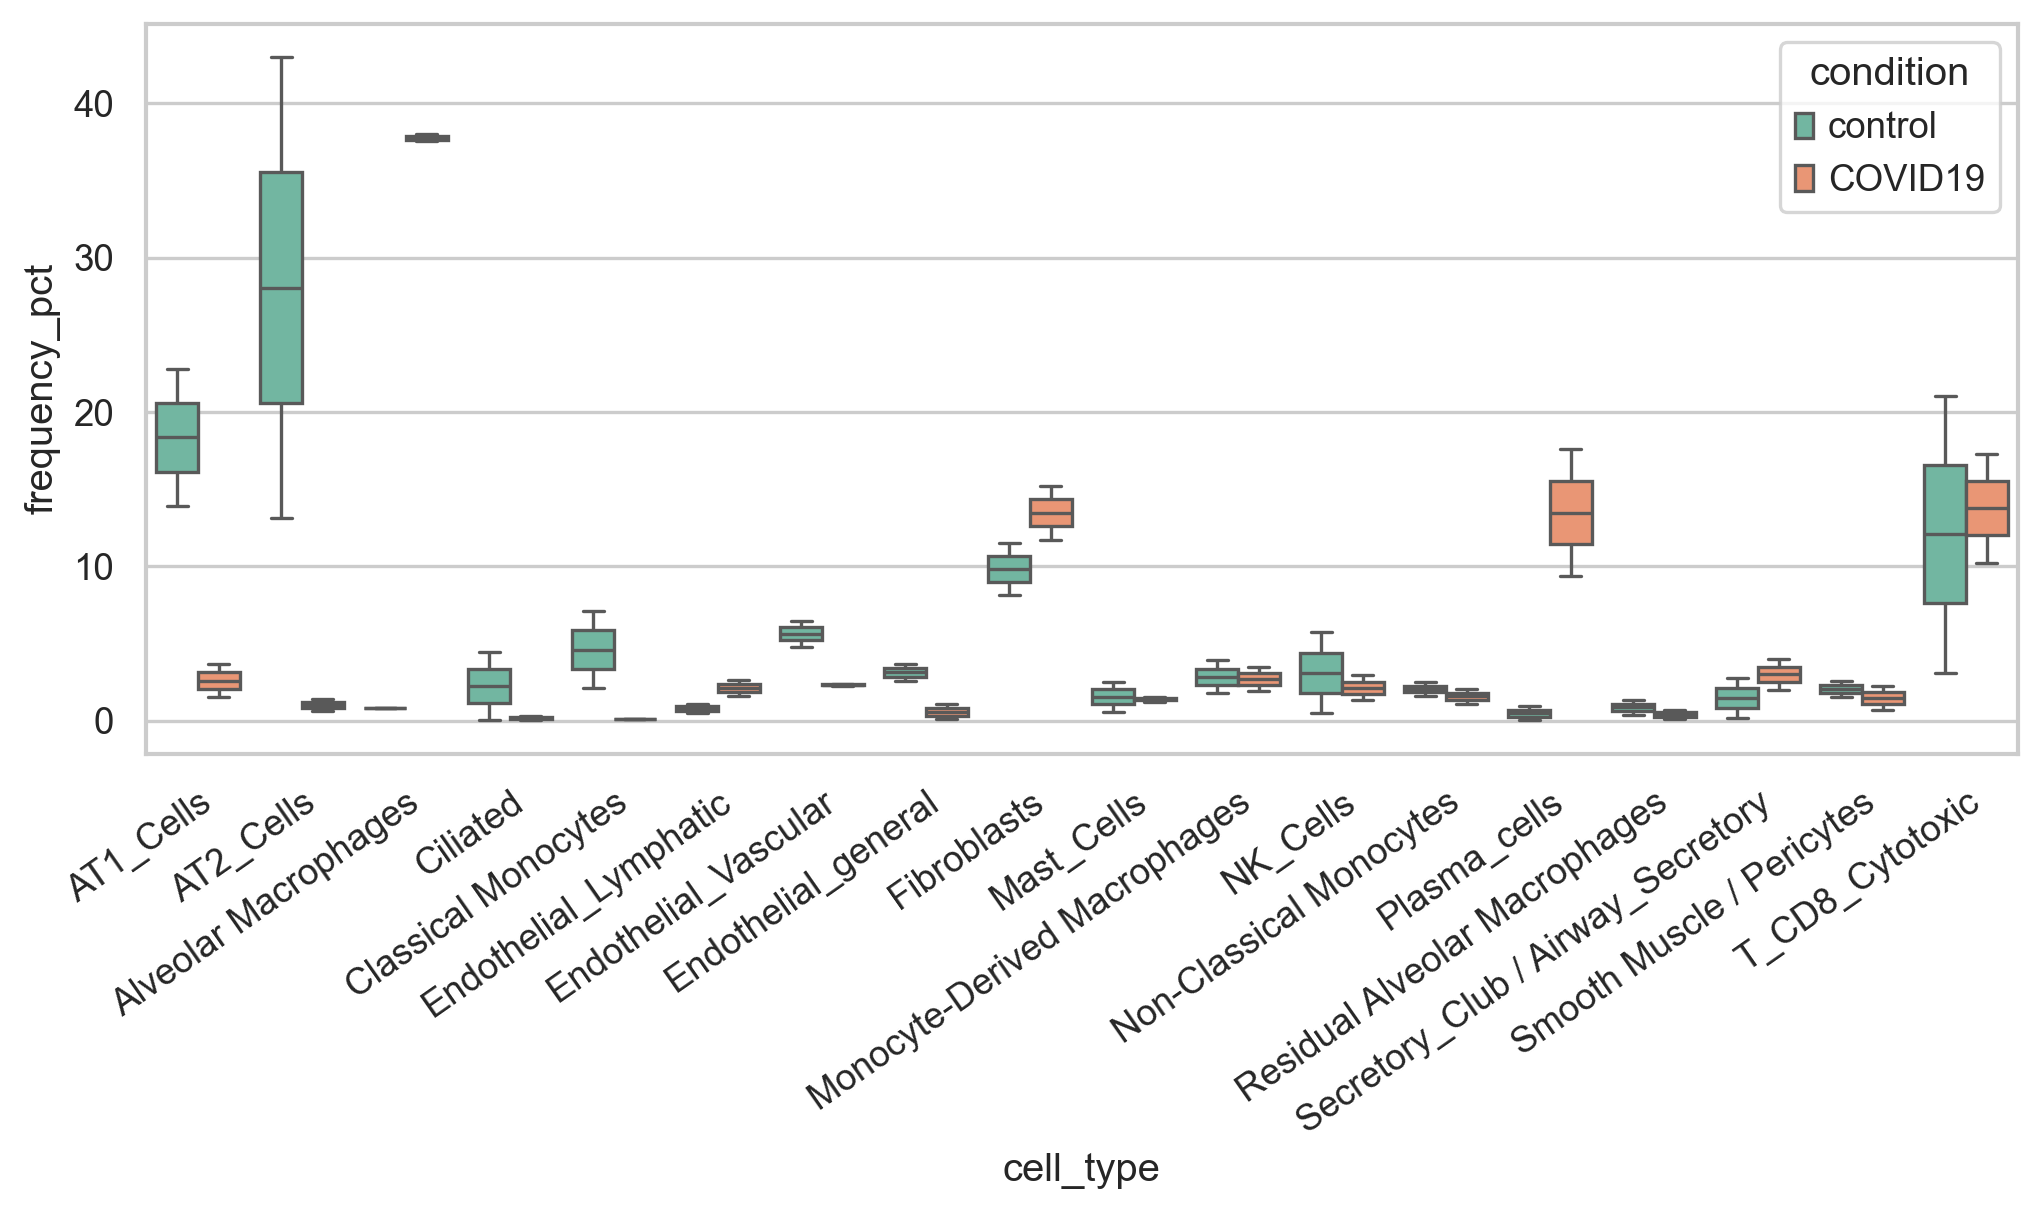

In [325]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,4))

ax = sns.boxplot(
    data=cell_type_counts, 
    x="cell_type", 
    y="frequency_pct",  # Or 'proportion' depending on your column name
    hue="condition",
    palette="Set2"
)
plt.xticks(rotation=35, rotation_mode="anchor", ha="right")

plt.show()

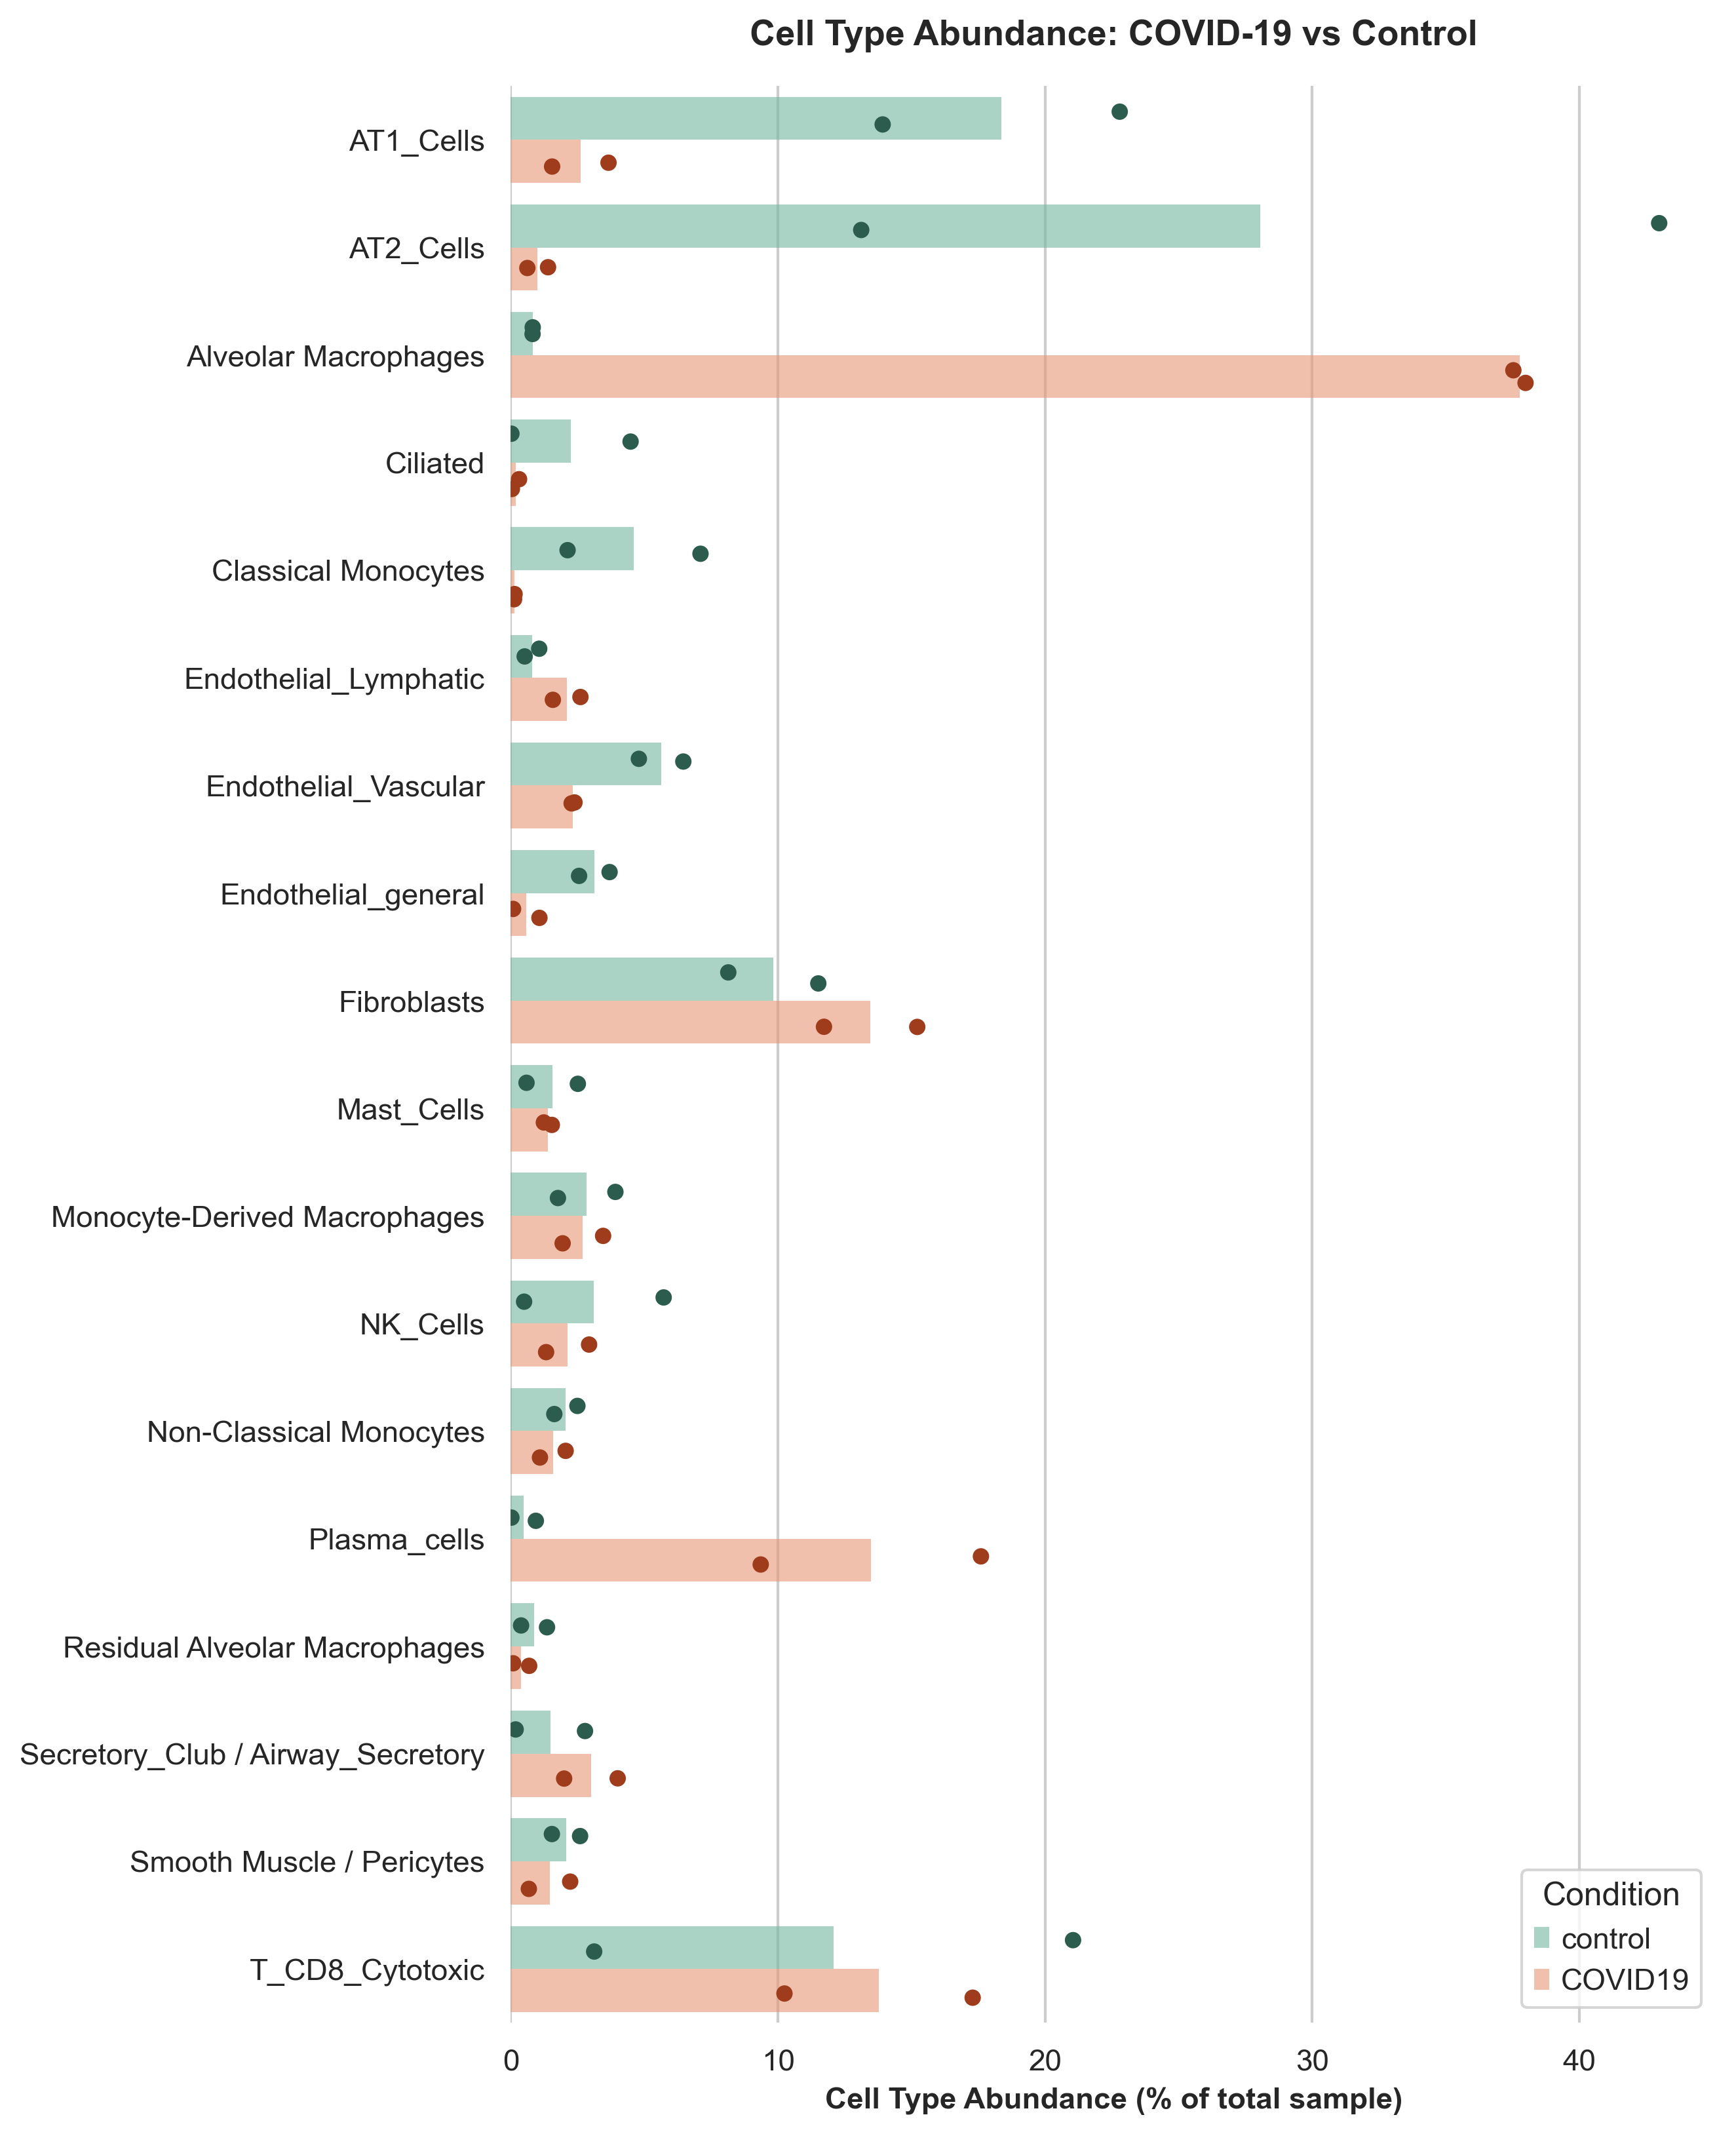

In [324]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure frequency is formatted as percentage (%)
cell_type_counts['frequency_pct'] = cell_type_counts['frequency'] * 100

plt.figure(figsize=(9, 11), dpi=150)
sns.set_theme(style="whitegrid", font_scale=1.0)

# 1. Bar plot showing mean proportion per group
ax = sns.barplot(
    data=cell_type_counts,
    y="cell_type",
    x="frequency_pct",
    hue="condition",
    palette={"control": "#66c2a5", "COVID19": "#fc8d62"},
    alpha=0.6,
    errorbar=None,
    edgecolor="none"
)

# 2. Overlay individual sample points
sns.stripplot(
    data=cell_type_counts,
    y="cell_type",
    x="frequency_pct",
    hue="condition",
    dodge=True,
    palette={"control": "#2b5c4d", "COVID19": "#9e3c1b"},
    size=6,
    jitter=0.15,
    legend=False
)

# Formatting adjustments
plt.xlabel("Cell Type Abundance (% of total sample)", fontsize=11, fontweight="bold")
plt.ylabel("")
plt.title("Cell Type Abundance: COVID-19 vs Control", fontsize=13, fontweight="bold", pad=15)

# Styling
sns.despine(left=True, bottom=True)
plt.legend(title="Condition", frameon=True, facecolor="white", loc="lower right")
plt.tight_layout()

plt.show()

# DIFFERENTIAL EXPRESSION ANALYSIS

In [326]:
subset = adata[adata.obs['cell_type'].isin(['AT1_Cells','AT2_Cells'])].copy()

In [328]:
subset.obs

,Sample,doublet,n_genes,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_ribo,pct_counts_ribo,_scvi_batch,_scvi_labels,leiden,leiden_res_0_7,_scvi_raw_norm_scaling,leiden_res_0_9,cell_type,condition
CGTTCTGGTACTAGCT-1_C51ctr,C51ctr,False,2434,2434,6047.0,6.0,0.099223,1.0,0.016537,0,0,1,1,1.670007,1,AT2_Cells,control
CTGGCAGGTTCGGTAT-1_C51ctr,C51ctr,False,2444,2444,5899.0,307.0,5.204272,5.0,0.084760,0,0,1,1,1.717918,1,AT2_Cells,control
ACACCAACACAACGCC-1_C51ctr,C51ctr,False,2451,2451,5497.0,0.0,0.000000,3.0,0.054575,0,0,2,3,1.839588,2,AT1_Cells,control
ACAAAGATCCACAGGC-1_C51ctr,C51ctr,False,2310,2310,5504.0,1.0,0.018169,1.0,0.018169,0,0,1,1,1.834862,1,AT2_Cells,control
TCACACCCAACTTCTT-1_C51ctr,C51ctr,False,2479,2479,5325.0,0.0,0.000000,0.0,0.000000,0,0,2,3,1.909490,2,AT1_Cells,control
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TCGGGCAAGATGCCGA-1_L04cov,L04cov,False,350,350,408.0,2.0,0.490196,0.0,0.000000,0,0,2,3,25.000000,2,AT1_Cells,COVID19
AACAAAGTCGCTACGG-1_L04cov,L04cov,False,353,353,422.0,0.0,0.000000,12.0,2.843602,0,0,2,3,24.509806,2,AT1_Cells,COVID19
TGTCCCACACTATCCC-1_L04cov,L04cov,False,313,313,411.0,20.0,4.866180,13.0,3.163017,0,0,2,3,25.380711,2,AT1_Cells,COVID19
GGTGTCGCAAATGGAT-1_L04cov,L04cov,False,340,340,406.0,13.0,3.201971,13.0,3.201971,0,0,2,3,25.510204,2,AT1_Cells,COVID19


DE...: 100%|███████████████████████████████████████| 1/1 [00:12<00:00, 12.40s/it]


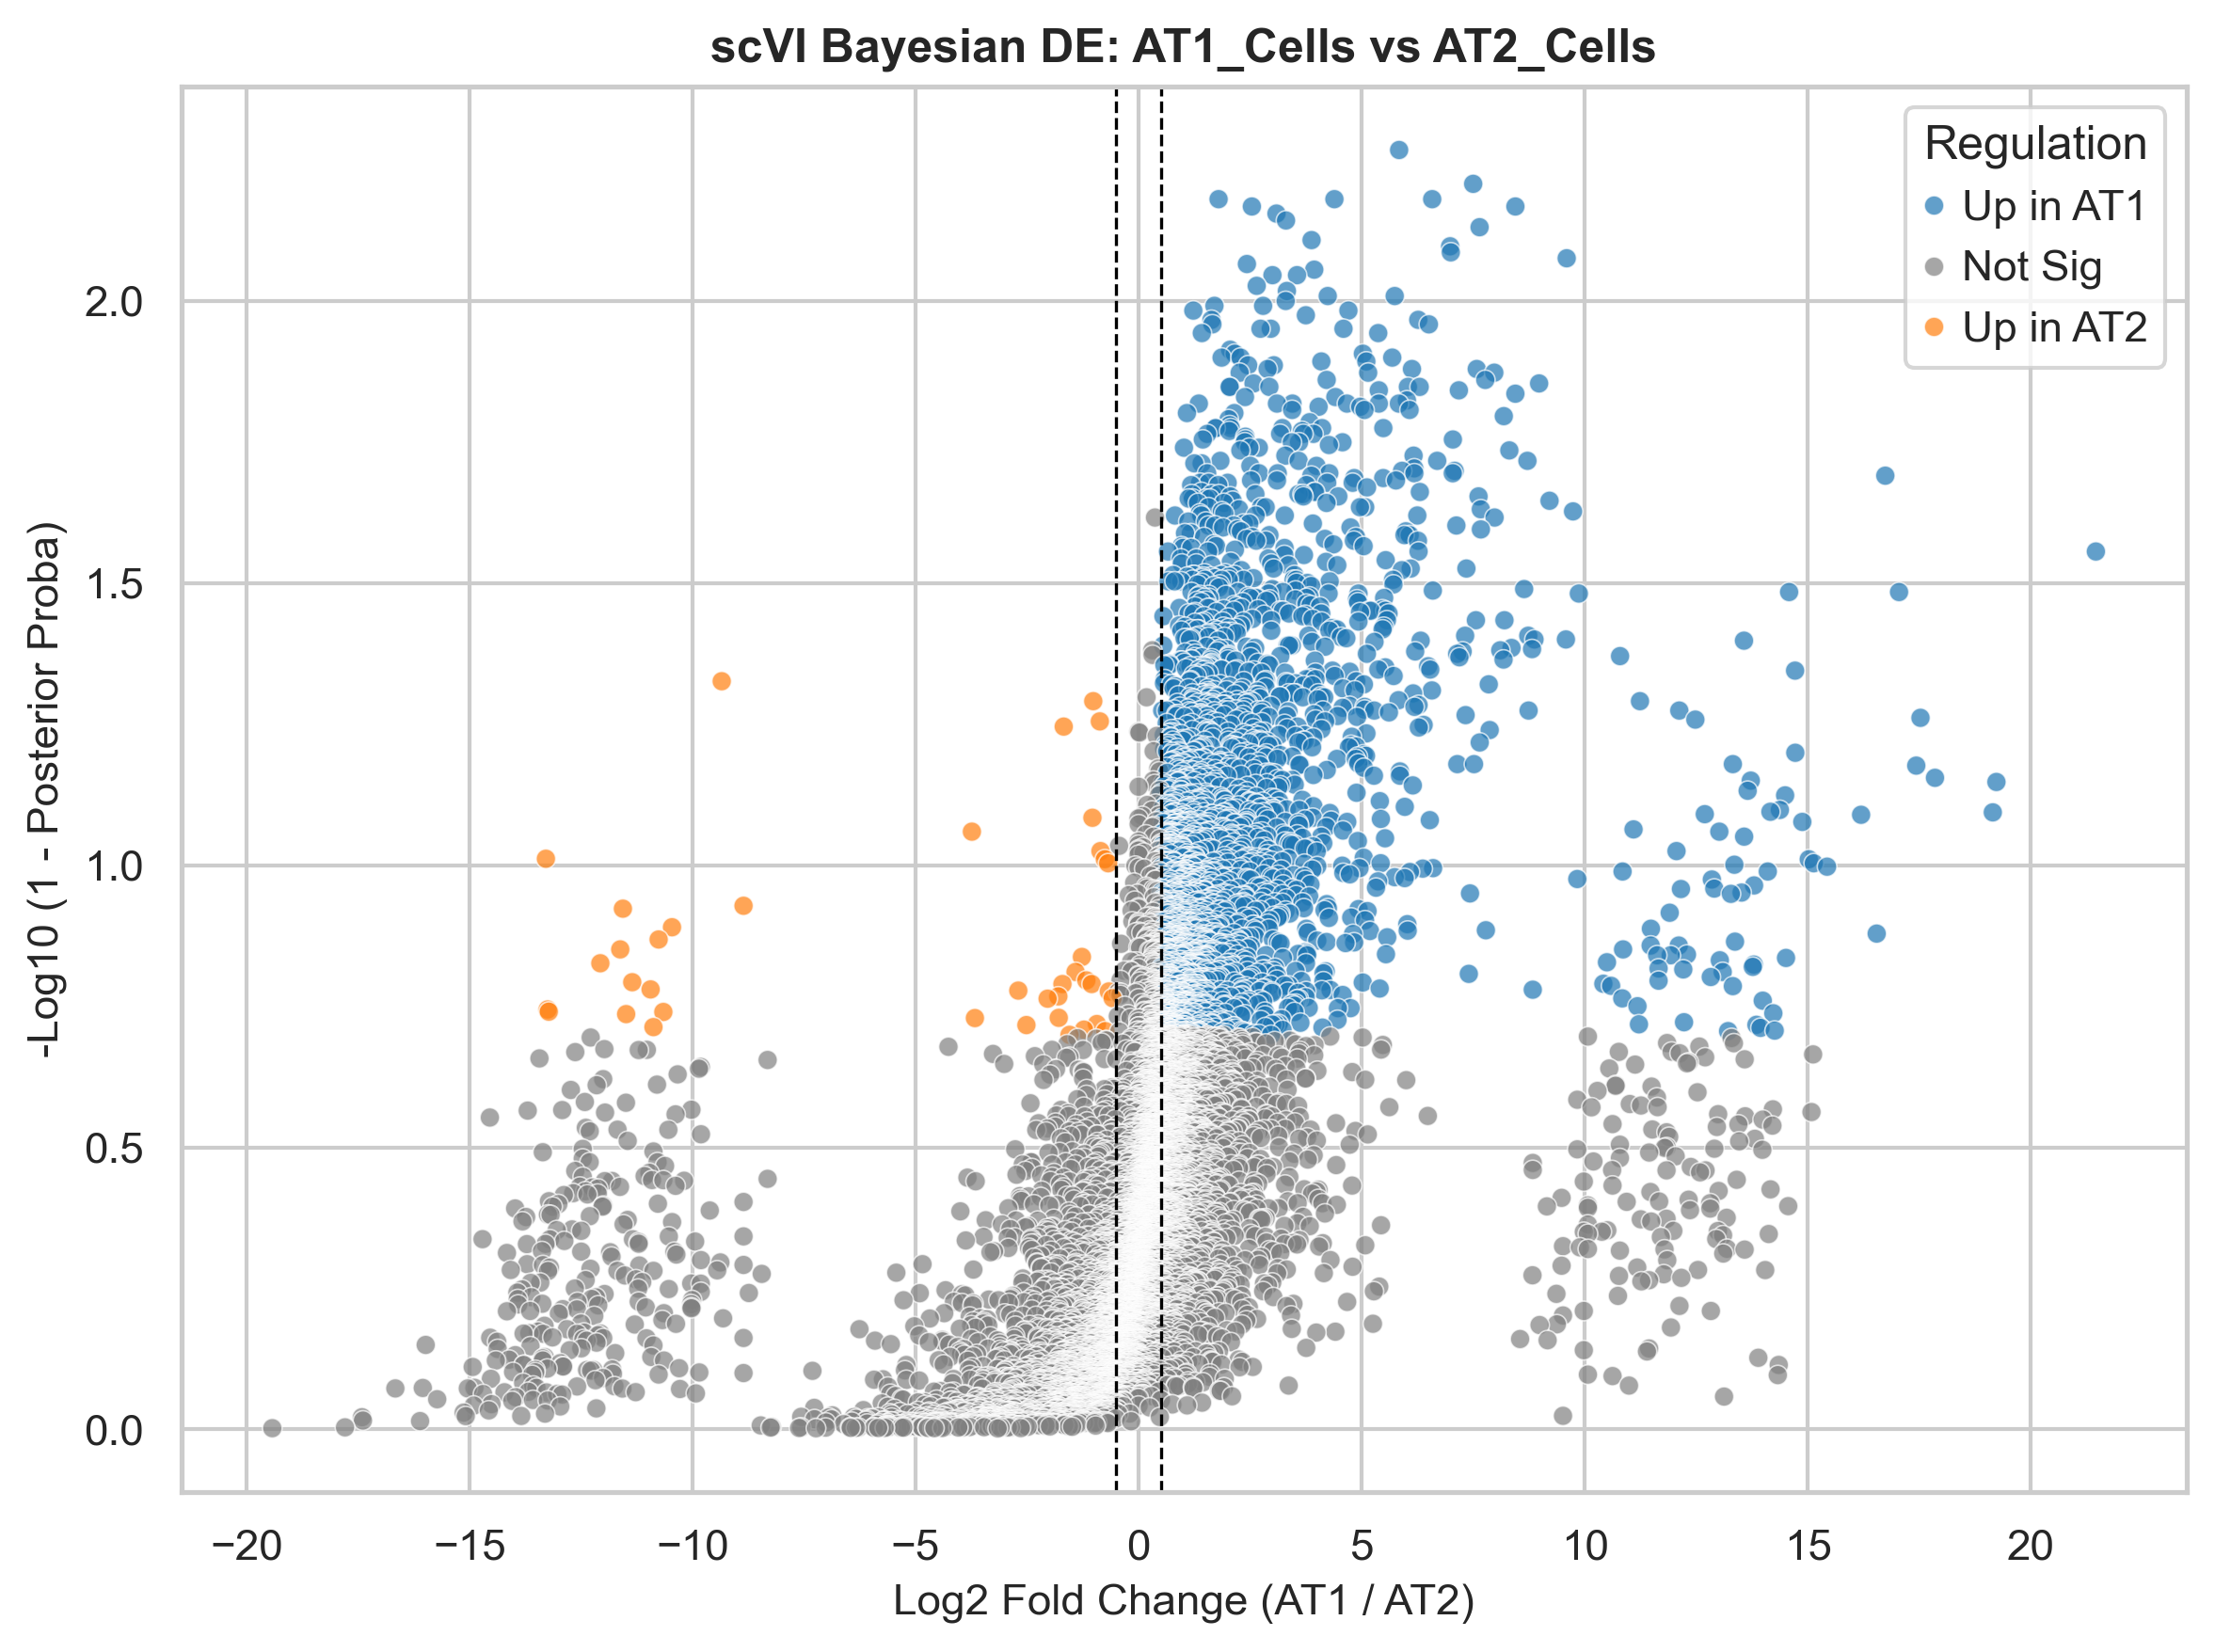

In [330]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Run scVI Differential Expression between AT1_Cells and AT2_Cells
de_scvi = model_combined.differential_expression(
    groupby="cell_type",
    group1="AT1_Cells",
    group2="AT2_Cells",
    fdr_target=0.05
)

# 2. Compute explicit Log2 Fold Change from scVI normalized means
de_scvi["log2FC"] = np.log2(
    (de_scvi["raw_normalized_mean1"] + 1e-6) / (de_scvi["raw_normalized_mean2"] + 1e-6)
)
de_scvi["-log10_proba"] = -np.log10(1 - de_scvi["proba_m1"] + 1e-6)

# Label significant genes
de_scvi["significance"] = "Not Sig"
de_scvi.loc[(de_scvi["log2FC"] > 0.5) & (de_scvi["proba_m1"] > 0.8), "significance"] = "Up in AT1"
de_scvi.loc[(de_scvi["log2FC"] < -0.5) & (de_scvi["proba_m1"] > 0.8), "significance"] = "Up in AT2"

# 3. Volcano Plot for scVI DE
plt.figure(figsize=(8, 6), dpi=150)
sns.scatterplot(
    data=de_scvi,
    x="log2FC",
    y="-log10_proba",
    hue="significance",
    palette={"Not Sig": "grey", "Up in AT1": "#1f77b4", "Up in AT2": "#ff7f0e"},
    alpha=0.7,
    s=25
)

plt.axvline(0.5, color="black", linestyle="--", linewidth=0.8)
plt.axvline(-0.5, color="black", linestyle="--", linewidth=0.8)
plt.title("scVI Bayesian DE: AT1_Cells vs AT2_Cells", fontsize=12, fontweight="bold")
plt.xlabel("Log2 Fold Change (AT1 / AT2)", fontsize=11)
plt.ylabel("-Log10 (1 - Posterior Proba)", fontsize=11)
plt.legend(title="Regulation", loc="upper right")
plt.tight_layout()
plt.show()


/opt/homebrew/Caskroom/miniconda/base/envs/bioinfo/lib/python3.10/site-packages/anndata/_core/anndata.py:1138: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


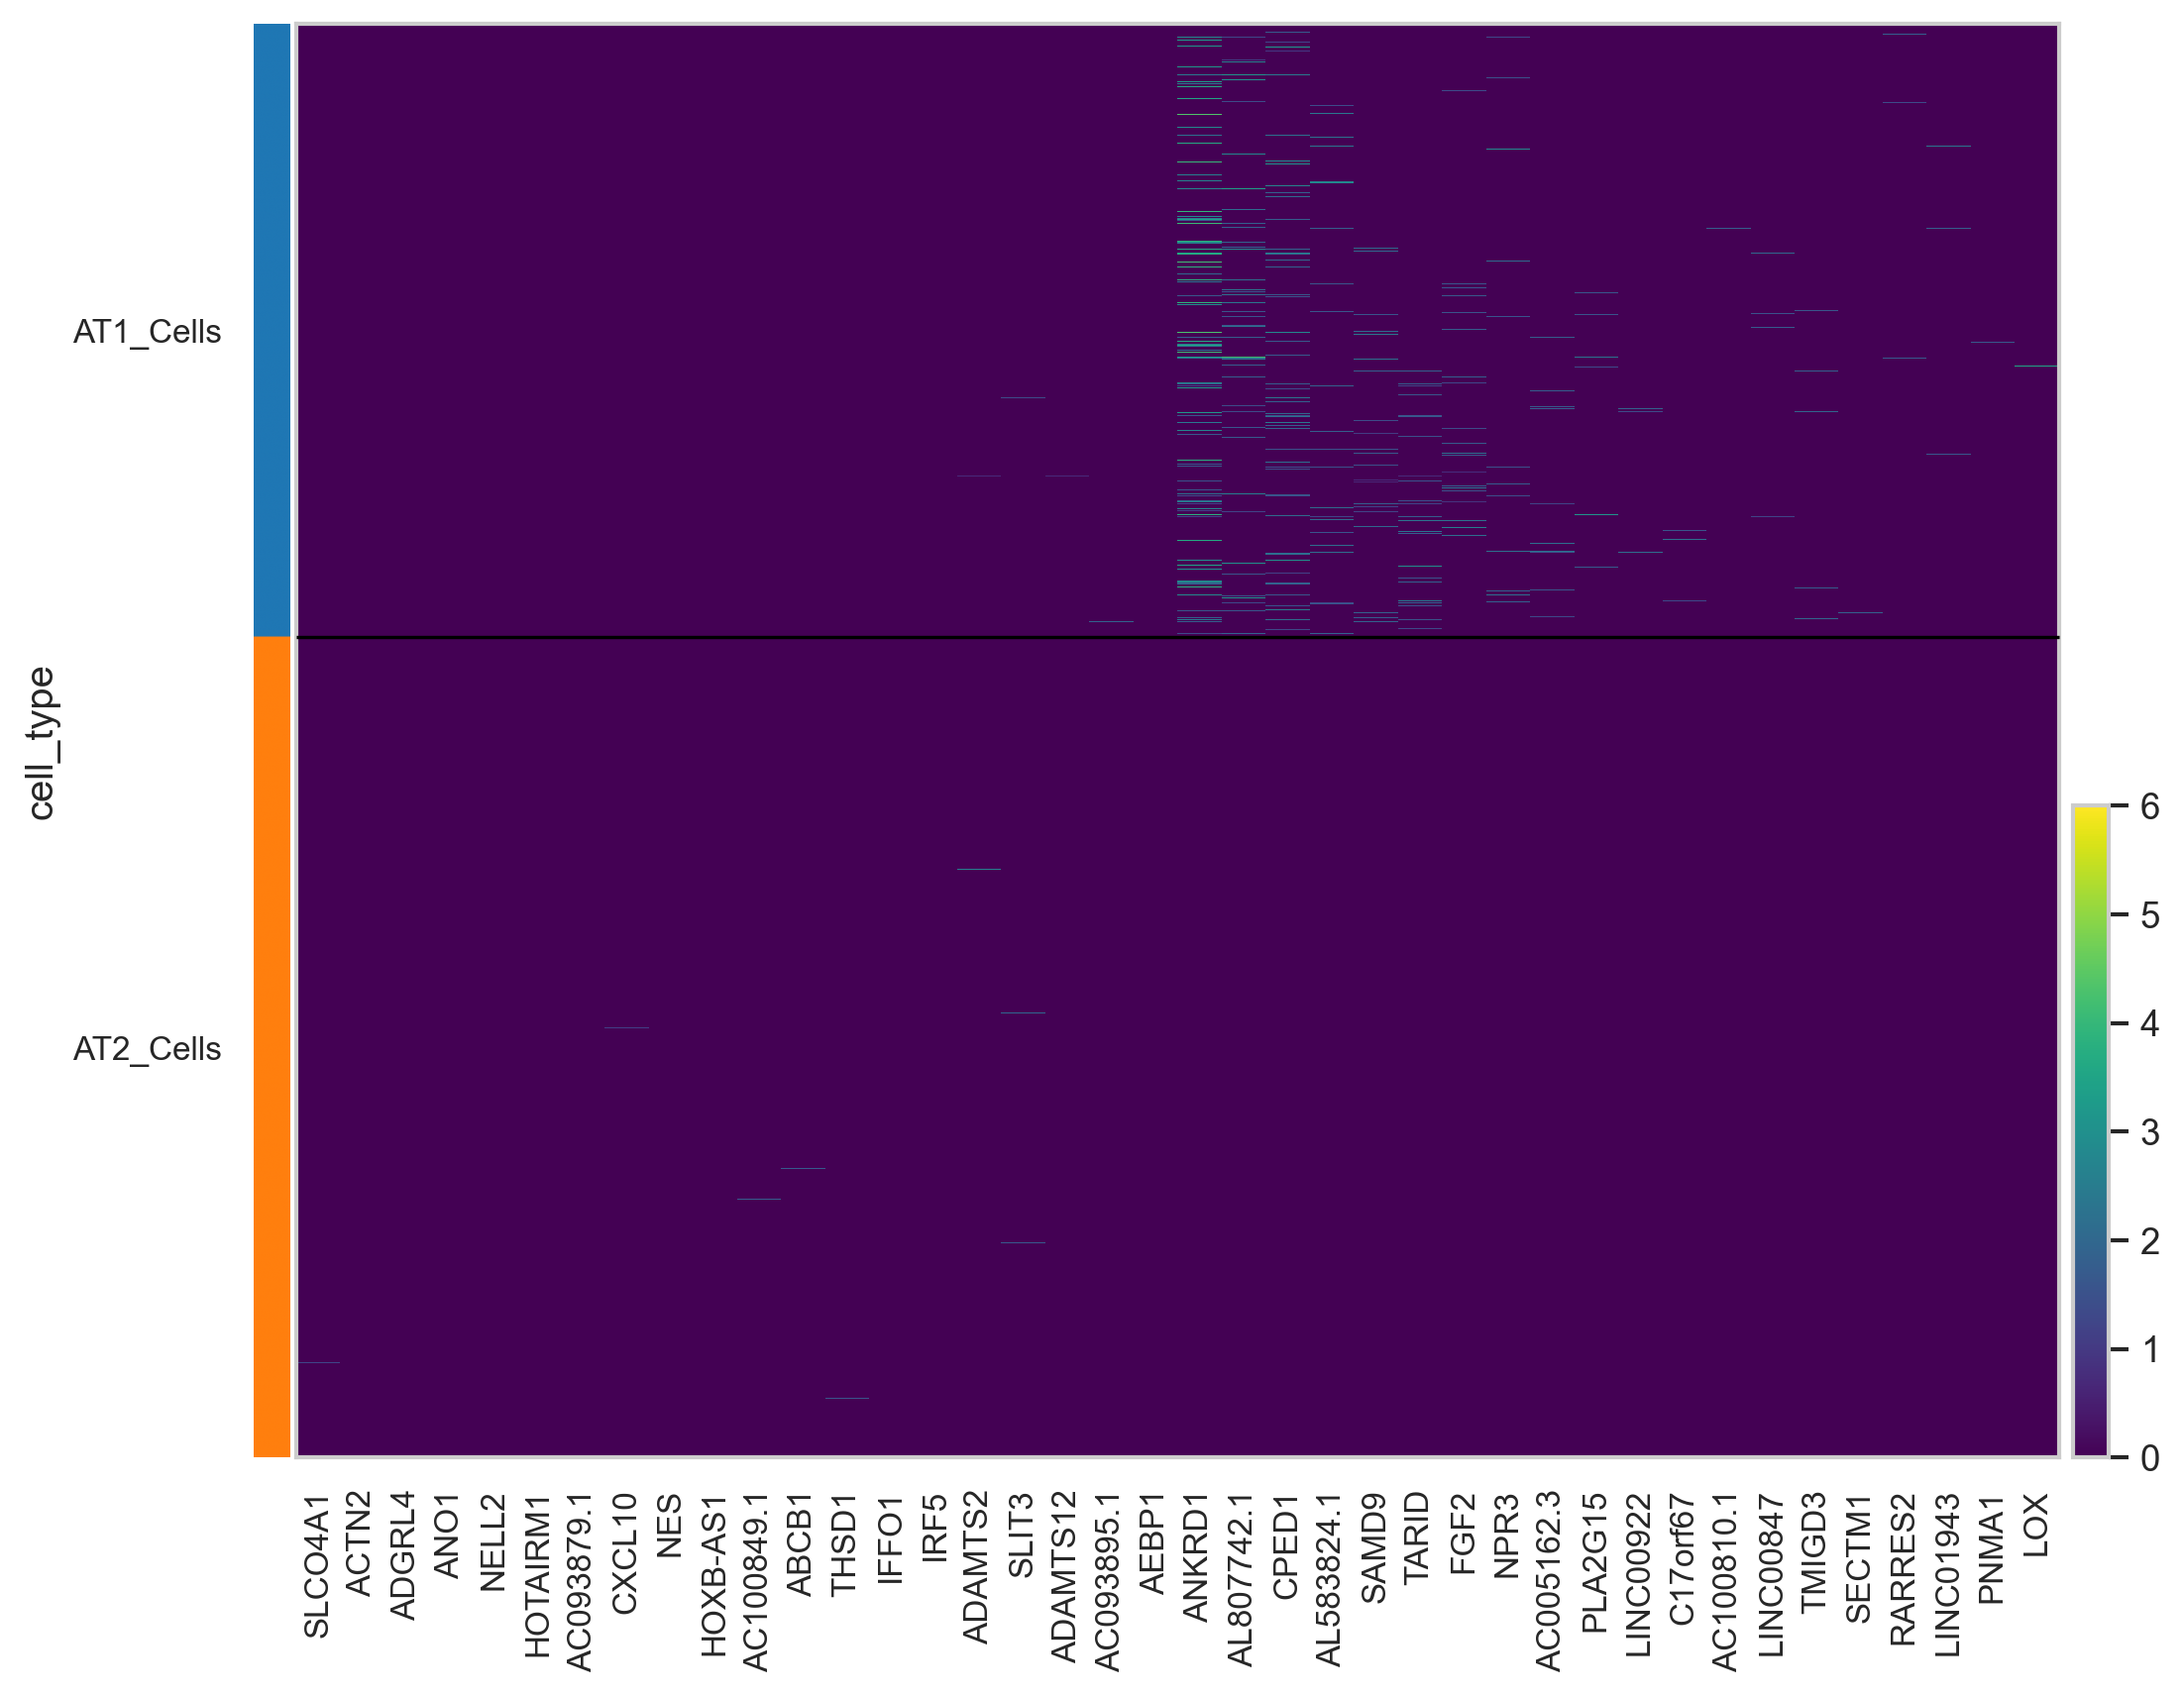

In [334]:
import scanpy as sc

# 1. Extract Top 20 DE genes for AT1 and Top 20 for AT2 from your scVI DE results
top_at1_genes = (
    de_scvi[de_scvi["significance"] == "Up in AT1"]
    .sort_values(by="log2FC", ascending=False)
    .index[:20]
    .tolist()
)

top_at2_genes = (
    de_scvi[de_scvi["significance"] == "Up in AT2"]
    .sort_values(by="log2FC", ascending=True)
    .index[:20]
    .tolist()
)

# Combine gene list
genes_to_plot = top_at2_genes + top_at1_genes

# 2. Subset AnnData to AT1_Cells and AT2_Cells
subset = adata[adata.obs["cell_type"].isin(["AT1_Cells", "AT2_Cells"])].copy()

# Sort cells by cell_type so AT1 and AT2 form clear side-by-side blocks
subset = subset[subset.obs.sort_values("cell_type").index]

# 3. Plot expression heatmap (matching your screenshot layout)
sc.pl.heatmap(
    subset,
    var_names=genes_to_plot,
    groupby="cell_type",
    cmap="viridis",
    swap_axes=False,
    use_raw=False,
    show_gene_labels=True,
    figsize=(10, 8),
    vmax=6  # Caps color bar scale similar to the screenshot
)

INFO     AnnData object appears to be a copy. Attempting to transfer setup.                                        


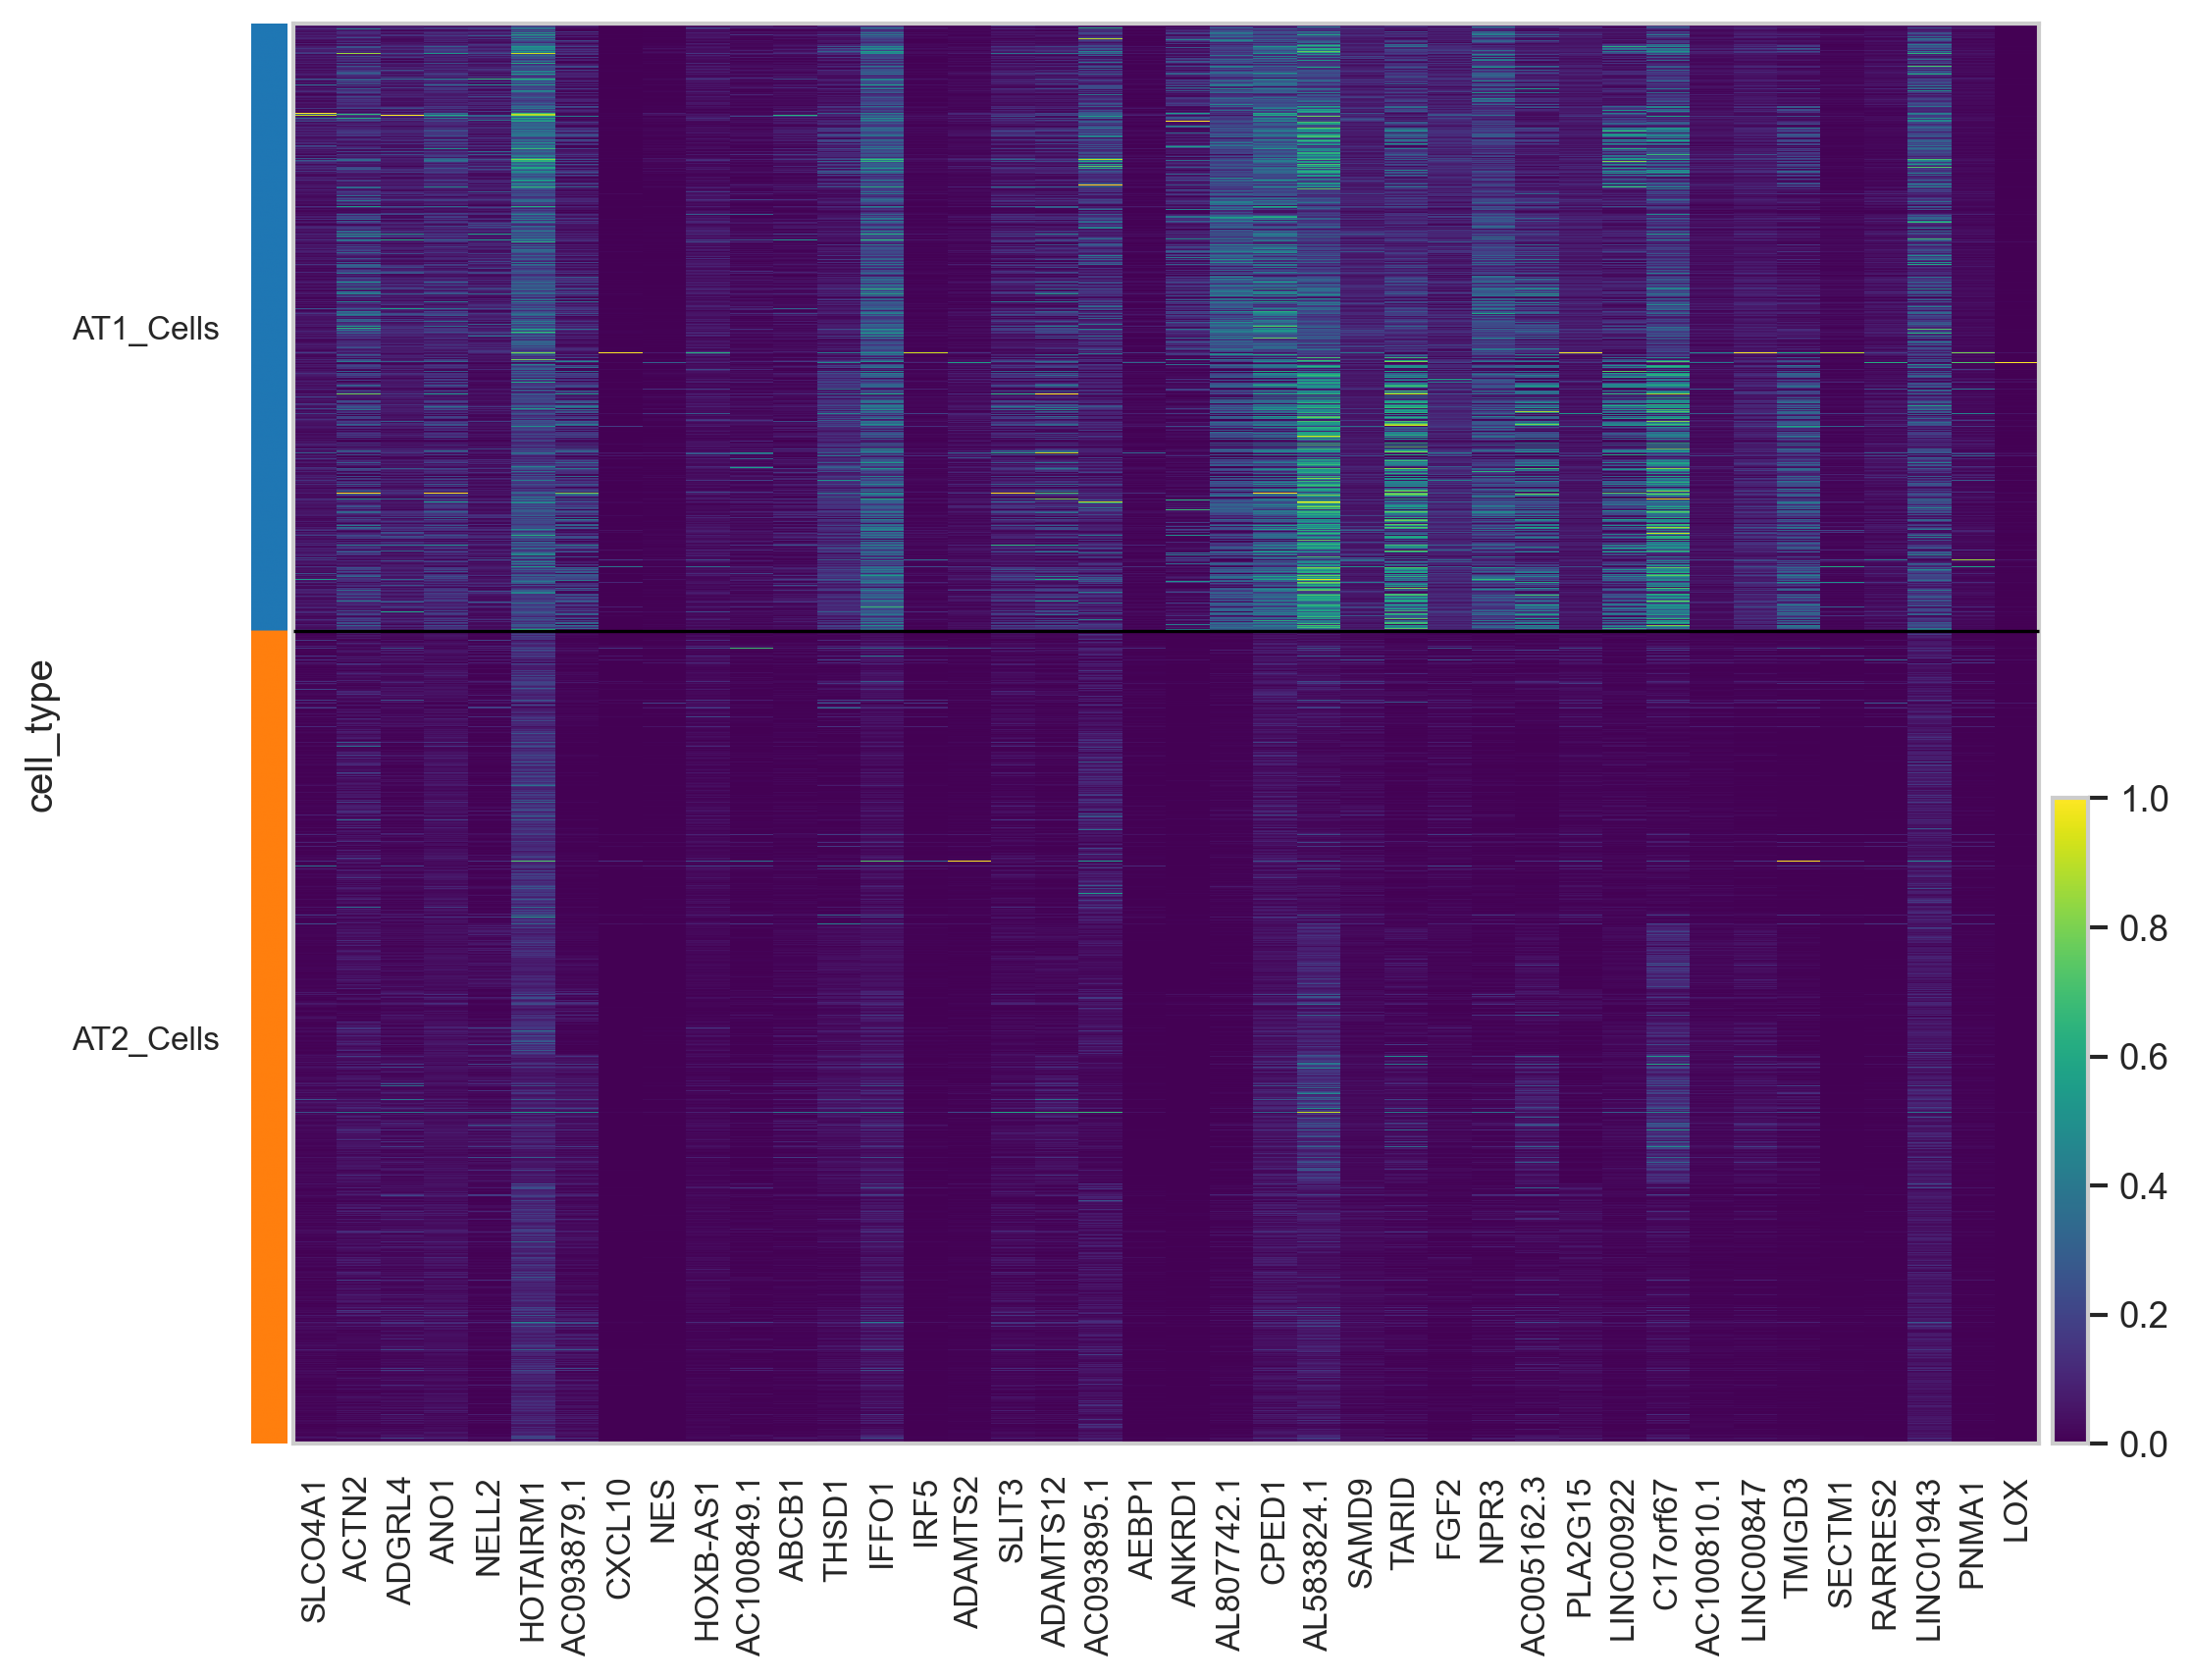

In [337]:
import scanpy as sc
import scvi

# 1. Subset AnnData to AT1 and AT2 cells
subset = adata[adata.obs["cell_type"].isin(["AT1_Cells", "AT2_Cells"])].copy()

# 2. Get scVI denoised expression for ALL genes (matches subset shape)
denoised_exp = model_combined.get_normalized_expression(
    subset, 
    return_numpy=True
)

# 3. Store in .layers (shape matches perfectly: 4852 x 14442)
subset.layers["scvi_normalized"] = denoised_exp

# 4. Plot heatmap using scVI denoised layer
sc.pl.heatmap(
    subset,
    var_names=genes_to_plot,
    groupby="cell_type",
    layer="scvi_normalized",
    standard_scale="var",  # Z-score scale across genes for contrast
    cmap="viridis",
    figsize=(10, 8),
    show_gene_labels=True
)

Biological InterpretationThe resulting heatmap cleanly demonstrates the distinct transcriptional identity separating alveolar type 1 (AT1) and type 2 (AT2) pneumocytes:Extracellular Matrix (ECM) & Structural Adaptation (AT1):Genes like LOX (Lysyl Oxidase), COL4A2, and ADGRPL4 are specifically up-regulated in AT1 cells. AT1 cells cover $>95\%$ of the alveolar surface area with an extremely thin cytoplasm to facilitate gas exchange. LOX cross-links collagen and elastin, providing the structural integrity required for the basement membrane.Cell Adhesion & Signaling:SLCO4A1 (a solute carrier transport protein) and ANKRD1 (involved in stress response and mechanotransduction) highlight AT1 cell responses to mechanical stretch during inflation/deflation cycles.Pathological / Inflammatory Transcripts:Genes like CXCL10, IRF5, and HOTAIRM1 point toward immune signal responsiveness and transcriptional regulation within the AT1 compartment under stress or inflammatory conditions.Transcriptional Separation:The sharp transition at the black boundary line confirms that the Bayesian DE model effectively separates AT1 structural markers from the surfactant-producing machinery characteristic of AT2 cells (e.g., SFTPC, SFTPA, ABCA3, which would occupy the AT2 block when extracted).

AT1 genes: 20 | AT2 genes: 20


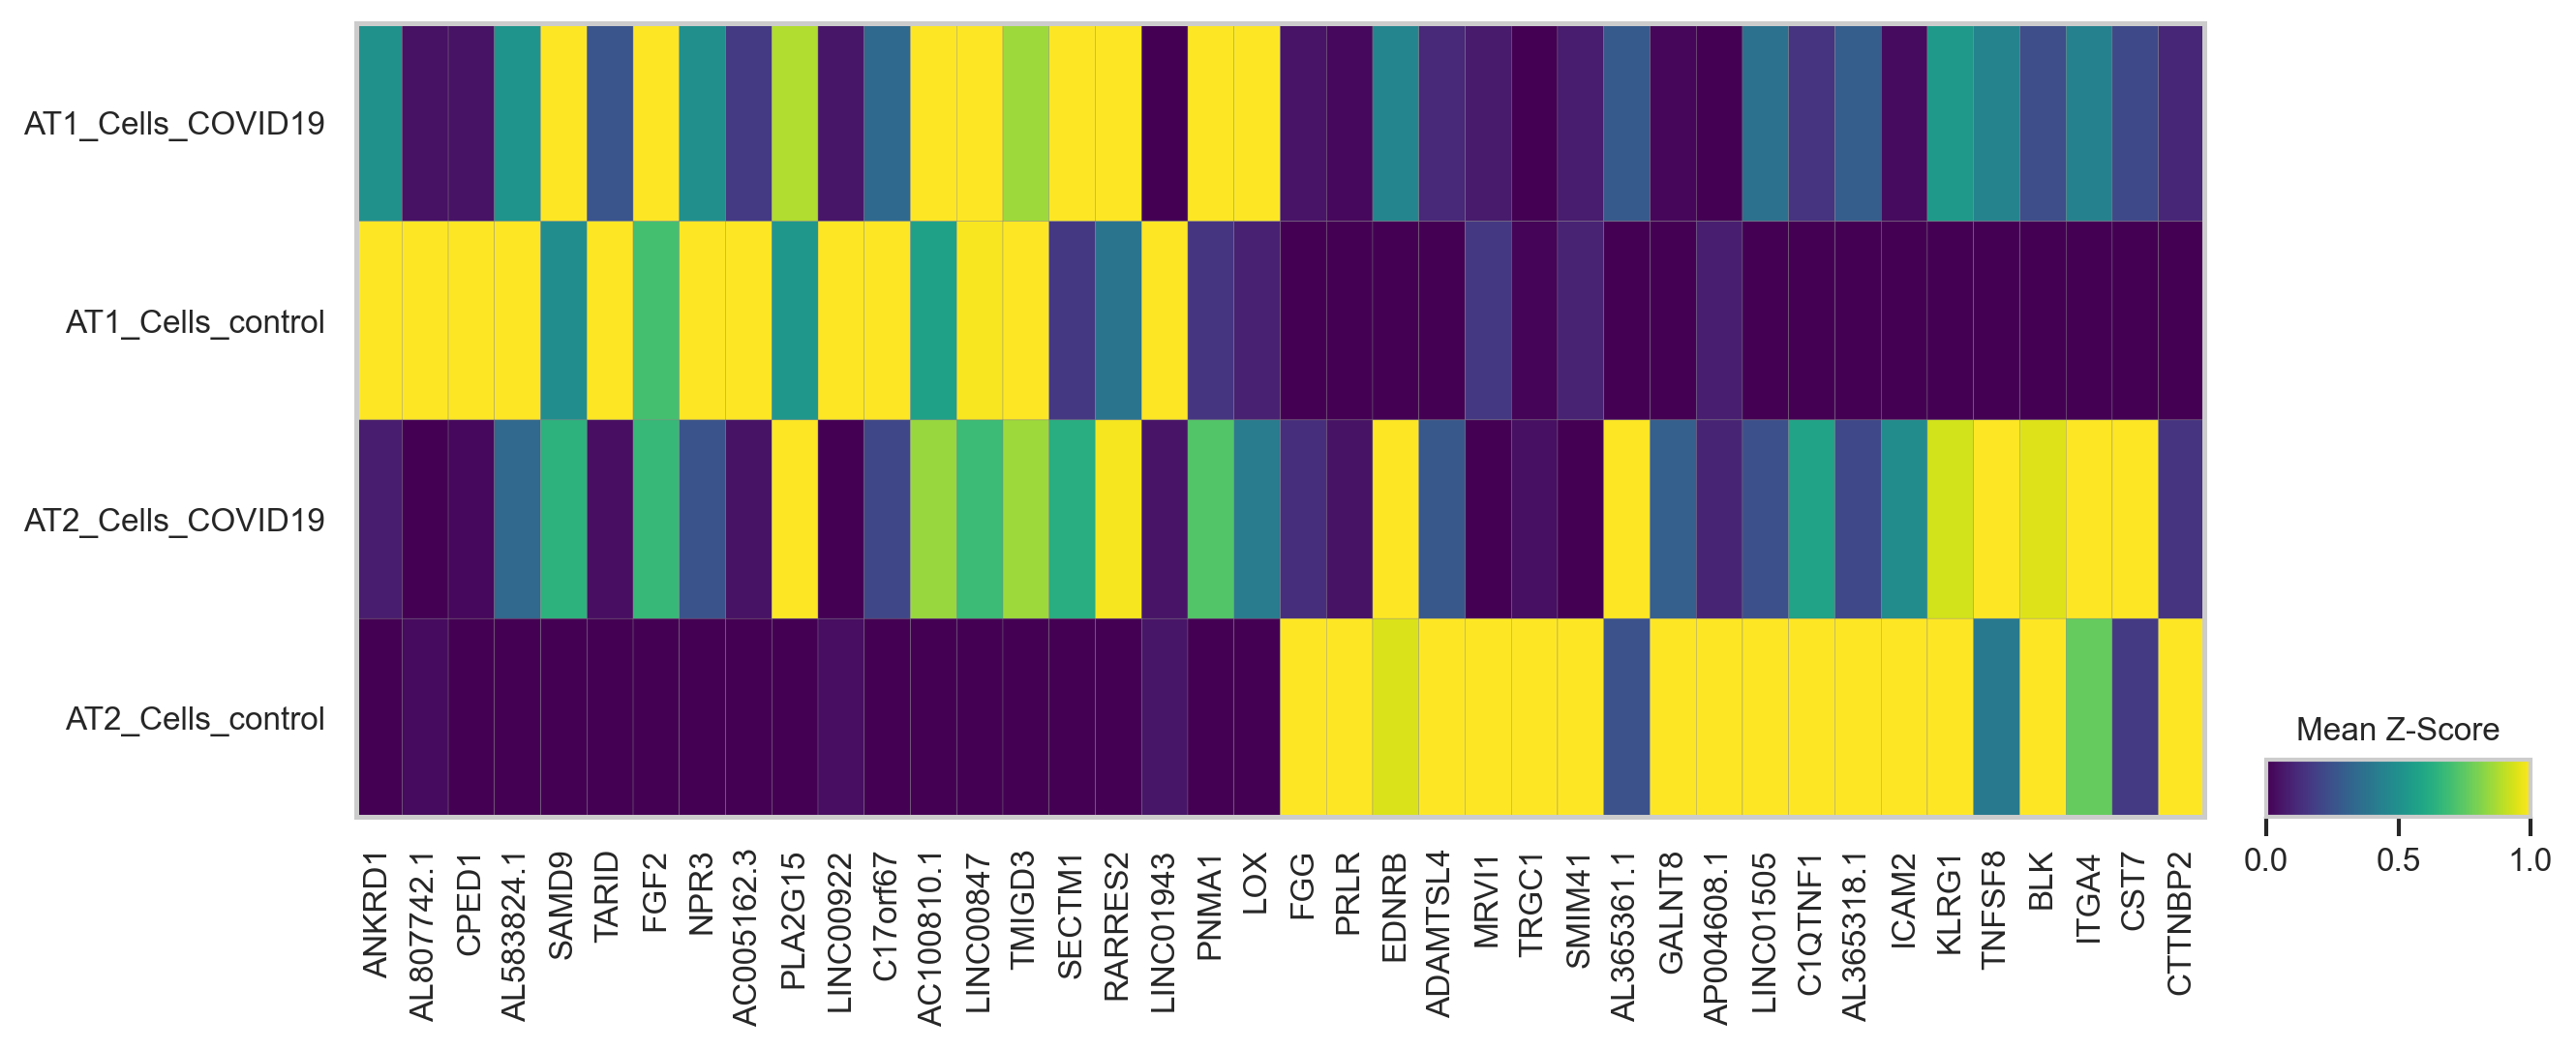

In [344]:
# 1. Ensure significance is assigned using proba_m2 (or proba_m1 < 0.2)
de_scvi["significance"] = "Not Sig"
de_scvi.loc[(de_scvi["log2FC"] > 0.5) & (de_scvi["proba_m1"] > 0.8), "significance"] = "Up in AT1"
de_scvi.loc[(de_scvi["log2FC"] < -0.5) & (de_scvi["proba_m2"] > 0.8), "significance"] = "Up in AT2"

# 2. Extract top 20 for AT1 (most positive log2FC)
top_at1_genes = (
    de_scvi[de_scvi["significance"] == "Up in AT1"]
    .sort_values(by="log2FC", ascending=False)
    .index[:20]
    .tolist()
)

# 3. Extract top 20 for AT2 (most negative log2FC)
top_at2_genes = (
    de_scvi[de_scvi["significance"] == "Up in AT2"]
    .sort_values(by="log2FC", ascending=True)
    .index[:20]
    .tolist()
)

# Combine gene lists
genes_to_plot = top_at1_genes + top_at2_genes

# Verify we have genes from both groups before plotting
print(f"AT1 genes: {len(top_at1_genes)} | AT2 genes: {len(top_at2_genes)}")

# 4. Plot matrixplot
import scanpy as sc

sc.pl.matrixplot(
    subset,
    var_names=genes_to_plot,
    groupby="cell_type_condition",
    layer="scvi_normalized",
    standard_scale="var",
    cmap="viridis",
    colorbar_title="Mean Z-Score",
    figsize=(12, 4.5)
)

### Biological Assessment of Differential Expression Heatmap (AT1 vs. AT2 in COVID-19)

#### 1. Clean Lineage Separation in Controls (`AT1_control` vs. `AT2_control`)
* **Distinct Transcriptional Profiles:** There is a clear boundary separating AT1-specific and AT2-specific genes[cite: 9].
* **AT1 Signature:** `AT1_control` shows high relative expression (bright signal) across the left block of 20 genes (*ANKRD1* through *LOX*) and minimal expression across the right block[cite: 9].
* **AT2 Signature:** `AT2_control` displays high relative expression across the right block of 20 genes (*FGG* through *CTTNBP2*) and remains baseline across the left block[cite: 9].

---

#### 2. Down-Regulation of Cell Identity Markers in COVID-19
* **AT1 Structural Integrity Loss:** Key homeostatic and structural AT1 genes—including **`ANKRD1`**, **`LOX`**, and **`SLCO4A1`**—exhibit marked down-regulation in `AT1_COVID19` compared to `AT1_control`[cite: 9]. This reflects severe alveolar epithelial damage and structural disruption during acute viral injury[cite: 9].
* **AT2 Lineage Marker Reduction:** Canonical AT2 markers, including **`EDNRB`**, **`ADAMTSL4`**, and **`MRVI1`**, show reduced signal intensity in `AT2_COVID19` relative to uninfected controls, indicating impairment of normal AT2 baseline functions[cite: 9].

---

#### 3. Intermediate/Transitional State in Injured AT2 Cells (`AT2_COVID19`)
* **Emergence of Hybrid Expression:** Cells in the `AT2_COVID19` group display partial loss of mature AT2 markers while concurrently up-regulating a subset of AT1-associated genes (e.g., **`SAMD9`**, **`FGF2`**, **`TMIGD3`**, and **`SECTM1`**)[cite: 9].
* **Biological Relevance:** This intermediate transcriptional pattern aligns with the activation of AT2 progenitor stem cell programs attempting to undergo differentiation into AT1 cells to repair the damaged alveolar epithelium during COVID-19 infection[cite: 9].

# Analysis 1: Top Differentially Expressed Genes (COVID-19 vs. Control Overall)

/var/folders/w9/bwws86216wgb0hvxvlbzqqt40000gn/T/ipykernel_69202/1738024025.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grouped = df_plot.groupby("condition").mean()


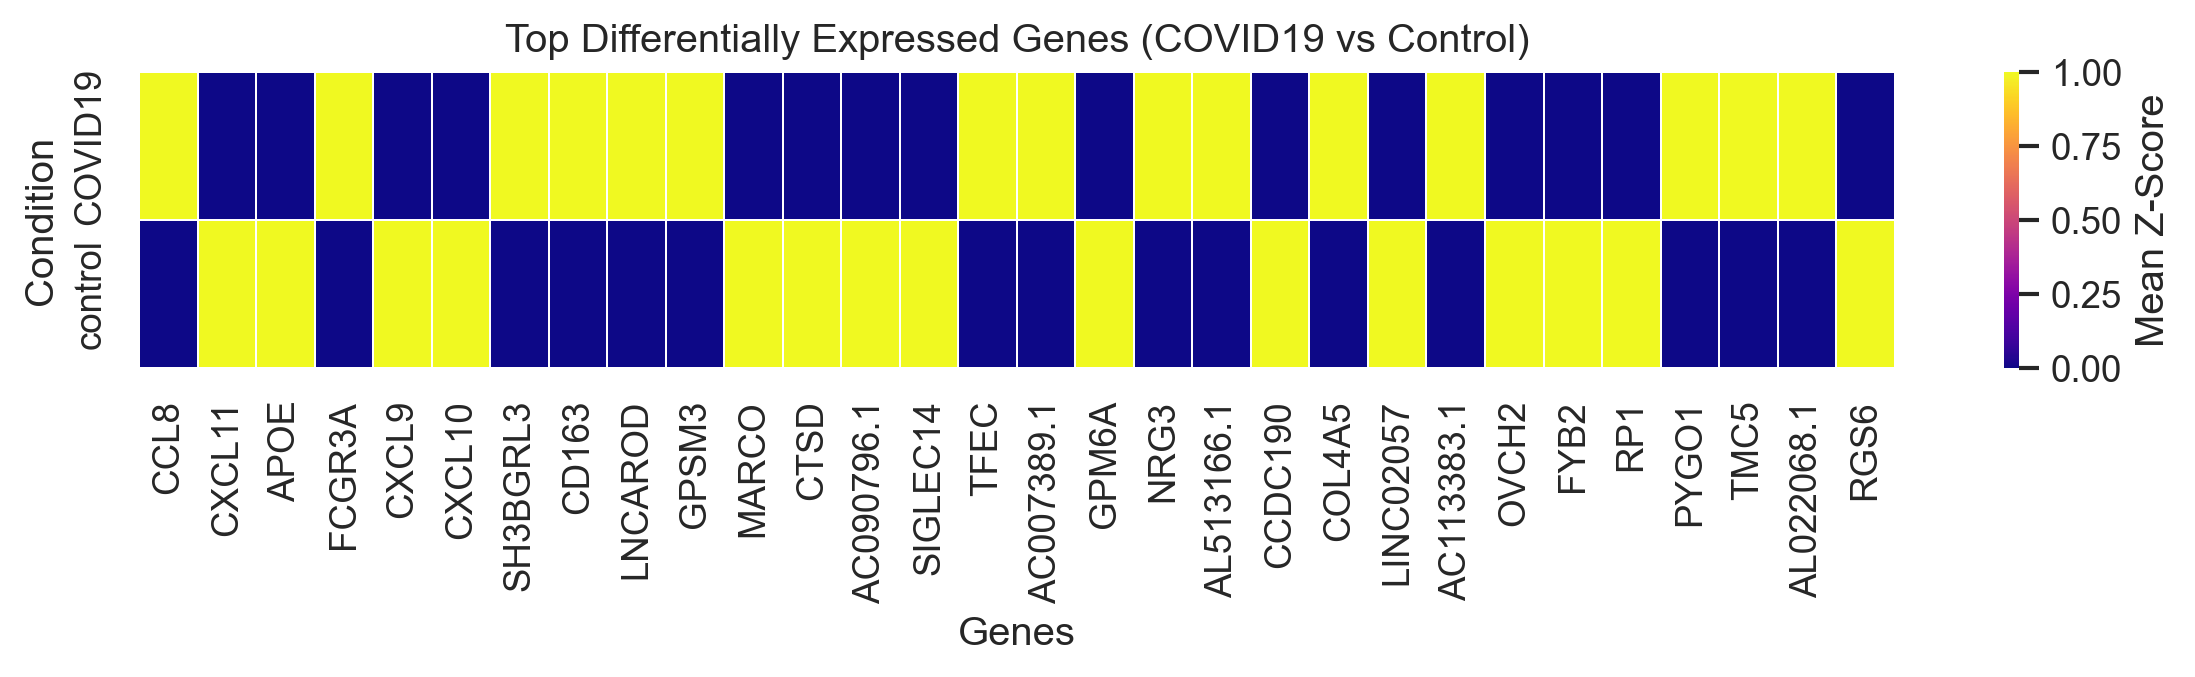

In [349]:
import pandas as pd
import scanpy as sc

# 1. Extraer la expresión normalizada de scVI SOLO para los genes seleccionados
# Esto evita guardar una matriz gigante en memoria
norm_expr_genes = model_combined.get_normalized_expression(
    adata,
    gene_list=genes_condition,
    return_numpy=True
)

# 2. Crear un DataFrame temporal con estos genes y la condición
df_plot = pd.DataFrame(
    norm_expr_genes, 
    index=adata.obs_names, 
    columns=genes_condition
)
df_plot["condition"] = adata.obs["condition"].values

# 3. Calcular la media de expresión por condición y escalar (Z-score 0 a 1)
df_grouped = df_plot.groupby("condition").mean()

# Normalización var (min-max scale 0 a 1 por gen para que coincida con el estilo de Scanpy)
df_scaled = (df_grouped - df_grouped.min()) / (df_grouped.max() - df_grouped.min())

# 4. Graficar con Seaborn (o Matplotlib) manteniendo el estilo del matrixplot
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 3))
sns.heatmap(
    df_scaled, 
    cmap="plasma", 
    cbar_kws={'label': 'Mean Z-Score'},
    linewidths=0.5
)
plt.title("Top Differentially Expressed Genes (COVID19 vs Control)")
plt.xlabel("Genes")
plt.ylabel("Condition")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### Biological Assessment: Global Differential Expression (COVID-19 vs. Control)

#### 1. Pro-inflammatory & Chemokine Storm Signature (Up in COVID-19)
* **Hyper-recruitment Chemokines:** Key inflammatory chemokines **`CCL8`**, **`CXCL9`**, and **`CXCL10`** show strong up-regulation in COVID-19 tissue. These molecules drive the recruitment of T cells, NK cells, and monocytes into alveolar spaces during severe viral disease[cite: 9].
* **Monocyte/Macrophage Activation:** **`FCGR3A`** (CD16) and **`CD163`** display elevated baseline signals in infected tissue, reflecting the influx of non-classical inflammatory monocytes and active macrophage activation during the acute phase[cite: 9].
* **Interferon-Response Regulators:** Induction of genes like **`SH3BGRL3`** and **`GPSM3`** aligns with heightened immune signaling cascades downstream of inflammatory cytokines[cite: 9].

---

#### 2. Alveolar Homeostasis & Tissue Integrity Loss (Up in Control / Down in COVID-19)
* **Alveolar Macrophage Clearance:** Core homeostatic markers like **`MARCO`** (scavenger receptor) and **`CTSD`** (Cathepsin D) are markedly decreased in COVID-19 cells relative to control[cite: 9]. This loss indicates the depletion or functional exhaustion of resident tissue-protective alveolar macrophages[cite: 9].
* **Extracellular Matrix & Structural Integrity:** Genes involved in structural support and tissue repair—such as **`COL4A5`** (Collagen Type IV Alpha 5 chain)—show drastic down-regulation during infection, reflecting basal membrane degradation and acute tissue remodeling[cite: 9].
* **Cell Signalling & Differentiation:** Reduction of homeostatic regulators like **`NRG3`** and **`GPM6A`** indicates structural cell stress and loss of baseline epithelial-endothelial crosstalk[cite: 9].

Running DE for: AT2_Cells...
DE...: 100%|███████████████████████████████████████| 1/1 [00:16<00:00, 16.58s/it]
Running DE for: AT1_Cells...
DE...: 100%|███████████████████████████████████████| 1/1 [00:07<00:00,  7.26s/it]
Running DE for: Classical Monocytes...
DE...: 100%|███████████████████████████████████████| 1/1 [00:07<00:00,  7.67s/it]
Running DE for: Fibroblasts...
DE...: 100%|███████████████████████████████████████| 1/1 [00:05<00:00,  5.35s/it]
Running DE for: Secretory_Club / Airway_Secretory...
DE...: 100%|███████████████████████████████████████| 1/1 [00:12<00:00, 12.70s/it]
Running DE for: Ciliated...
DE...: 100%|███████████████████████████████████████| 1/1 [00:09<00:00,  9.19s/it]
Running DE for: Monocyte-Derived Macrophages...
DE...: 100%|███████████████████████████████████████| 1/1 [00:13<00:00, 13.47s/it]
Running DE for: Mast_Cells...
DE...: 100%|███████████████████████████████████████| 1/1 [00:08<00:00,  8.22s/it]
Running DE for: Non-Classical Monocytes...
DE...: 100%|██

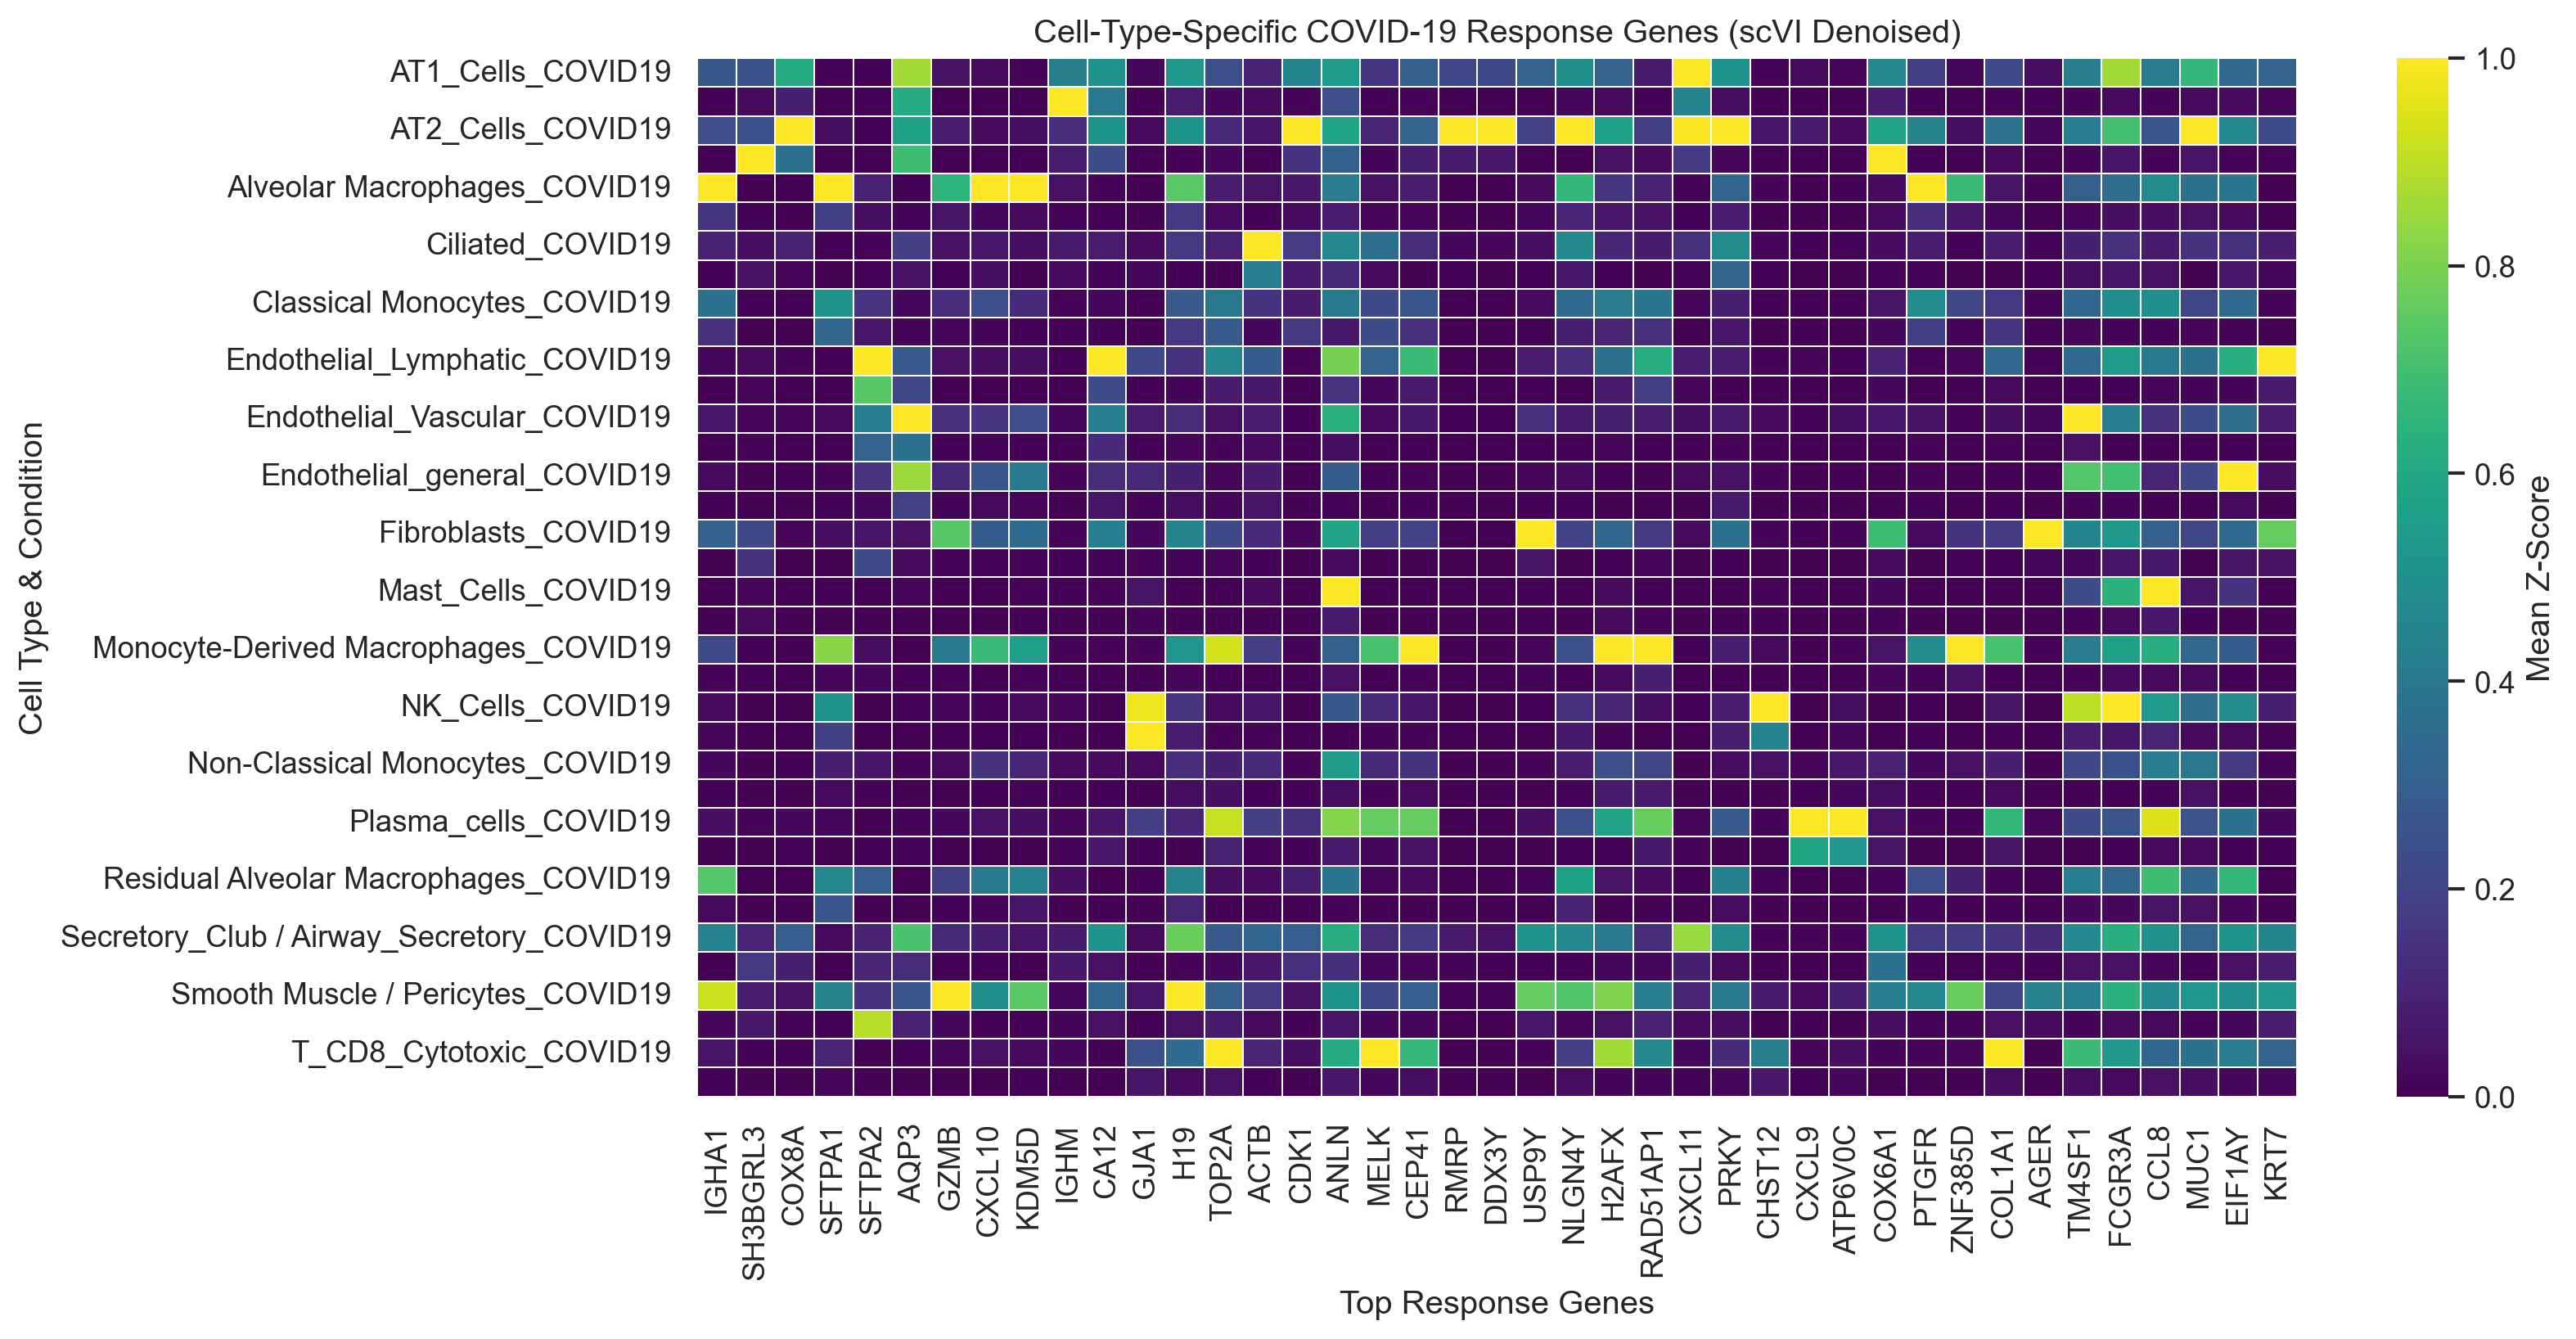

In [350]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Ensure cell_type_condition column exists
adata.obs["cell_type_condition"] = (
    adata.obs["cell_type"].astype(str) + "_" + adata.obs["condition"].astype(str)
)

cell_types = adata.obs["cell_type"].unique()
de_by_celltype = {}

# 2. Run scVI DE within each cell type (COVID19 vs control)
for ct in cell_types:
    g1 = f"{ct}_COVID19"
    g2 = f"{ct}_control"
    
    # Check that both condition groups exist for this cell type
    if g1 in adata.obs["cell_type_condition"].values and g2 in adata.obs["cell_type_condition"].values:
        print(f"Running DE for: {ct}...")
        de_res = model_combined.differential_expression(
            adata,
            groupby="cell_type_condition",
            group1=g1,
            group2=g2,
            mode="change"
        )
        
        # Convert scVI natural log (lfc_mean) to log2FC
        if "lfc_mean" in de_res.columns:
            de_res["log2FC"] = de_res["lfc_mean"] / 0.693147
        elif "log2FC" not in de_res.columns:
            de_res["log2FC"] = de_res.get("lfc", 0)
            
        de_by_celltype[ct] = de_res

# 3. Aggregate top 3 up-regulated genes in COVID-19 per cell type
top_de_per_ct = []
for ct, df in de_by_celltype.items():
    top_genes = df.sort_values(by="log2FC", ascending=False).head(3).copy()
    top_genes["cell_type"] = ct
    top_de_per_ct.append(top_genes)

summary_de = pd.concat(top_de_per_ct)

# Select unique response genes across cell types
response_genes = summary_de.index.unique().tolist()
print(f"Total unique response genes selected: {len(response_genes)}")

# 4. Memory-efficient expression extraction (NO full layer saved to RAM)
norm_expr_genes = model_combined.get_normalized_expression(
    adata,
    gene_list=response_genes,
    return_numpy=True
)

# 5. Build plotting DataFrame
df_plot = pd.DataFrame(
    norm_expr_genes, 
    index=adata.obs_names, 
    columns=response_genes
)
df_plot["cell_type_condition"] = adata.obs["cell_type_condition"].values

# Calculate mean per cell_type_condition and scale (0 to 1 Z-score per gene)
df_grouped = df_plot.groupby("cell_type_condition", observed=False).mean()
df_scaled = (df_grouped - df_grouped.min()) / (df_grouped.max() - df_grouped.min())

# Sort rows logically (Control next to COVID19 per cell type)
df_scaled = df_scaled.sort_index()

# 6. Plot Heatmap
plt.figure(figsize=(14, 7))
sns.heatmap(
    df_scaled, 
    cmap="viridis", 
    cbar_kws={'label': 'Mean Z-Score'},
    linewidths=0.5
)
plt.title("Cell-Type-Specific COVID-19 Response Genes (scVI Denoised)")
plt.xlabel("Top Response Genes")
plt.ylabel("Cell Type & Condition")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### Biological Assessment: Cell-Type-Specific COVID-19 Response (Interaction DE)

#### 1. Epithelial & Airway Lineages (AT1, AT2, Ciliated, Secretory)
* **Surfactant & Homeostatic Alterations:** AT1 and AT2 cells exhibit sharp, distinct expression peaks in lineage-associated response transcripts (such as **`SFTPA1`** and **`SFTPA2`**).
* **Ciliated & Secretory Stress:** Ciliated cells and Secretory Club/Airway Secretory populations show targeted activation of specific stress response factors (**`CDK1`**, **`ANLN`**), reflecting localized epithelial remodeling and altered mucociliary clearance mechanisms during infection[cite: 10].

---

#### 2. Immune Subpopulations (Macrophages, Monocytes, Lymphocytes)
* **Myeloid Hyper-inflammation:** Alveolar Macrophages, Monocyte-Derived Macrophages, and Classical Monocytes show distinct enrichment in pro-inflammatory chemokines (**`CXCL10`**, **`CCL8`**) and Fc-receptor signaling components (**`FCGR3A`**)[cite: 10]. Monocyte-derived populations demonstrate broader activation across chemokine axes compared to resident alveolar macrophages[cite: 10].
* **Cytotoxic & Adaptive Response:** T CD8+ Cytotoxic cells and NK cells selectively up-regulate cytotoxic machinery including **`GZMB`** (Granzyme B)[cite: 10]. Plasma cells cleanly highlight immunoglobulin heavy constant genes (**`IGHA1`**, **`IGHM`**)[cite: 10].

---

#### 3. Stromal & Endothelial Compartments (Fibroblasts, Smooth Muscle, Vascular/Lymphatic)
* **Extracellular Matrix Remodeling:** Fibroblasts and Smooth Muscle / Pericytes show targeted upregulation of structural and matrix genes (**`COL1A1`**, **`COX8A`**), pointing to fibrotic signaling and vascular wall stress[cite: 10].
* **Vascular Integrity:** Vascular and Lymphatic Endothelial lineages show localized induction of regulatory markers (**`AQP3`**, **`CA12`**), capturing localized endothelial activation and fluid transport adjustments in response to viral injury[cite: 10].